# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: Claude (Anthropic), used to help write and test the code and the discussion text

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [4]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [11]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

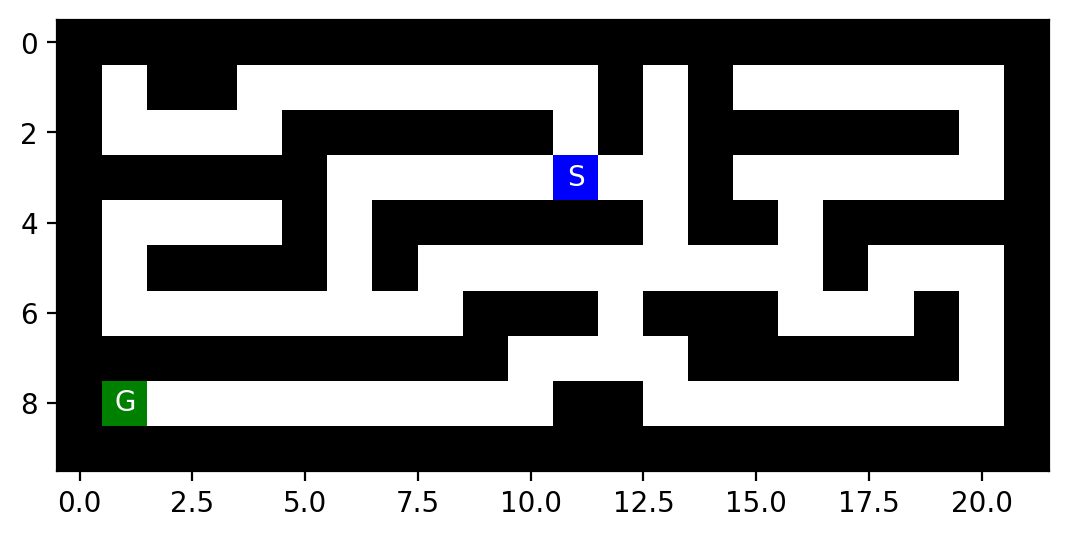

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [3]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [12]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['S', 'N', 'E', 'E', 'S', 'E', 'W', 'E', 'S', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [13]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: W
Following plan... step 1: E
Following plan... step 2: S
Following plan... step 3: N
Following plan... step 4: S
Following plan... step 5: N
Following plan... step 6: W
Following plan... step 7: W
Following plan... step 8: S
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [4]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search
        self.n_children = 0      # added field: number of children still alive (used by DFS to free memory)

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### Formal problem definition

The maze is a grid. A **state** is the position `(row, col)` of the agent on a square that is not a wall. The squares are the only thing that matters for planning, so a state does not need more information than the position.

* **Initial state:** the position of the square marked `S` (found with `find_pos(maze, "S")`).
* **Actions:** `ACTIONS(s)` $\subseteq \{N, E, S, W\}$ = move one square up, right, down or left. An action is applicable in $s$ if the square it leads to is inside the maze and is not a wall `X`.
* **Transition model:** $\text{RESULT}((r, c), a) = (r + \Delta r,\; c + \Delta c)$ with $\Delta N = (-1, 0)$, $\Delta E = (0, +1)$, $\Delta S = (+1, 0)$, $\Delta W = (0, -1)$. It is deterministic: the same action in the same state always leads to the same square.
* **Goal state:** $\text{IS-GOAL}(s)$ is true if $s$ is a square marked `G`. I store the goals as a *set* so that the same code also works for mazes with several goals (advanced task).
* **Path cost:** every action costs 1: $c(s, a, s') = 1$. The path cost $g(n)$ is the number of steps, which is also the depth of node $n$ in the tree and the length of the plan.

The code below implements exactly these components. The maze is only **read** by the transition model; it is never changed during the search.

In [14]:
import numpy as np
import maze_helper as mh
from collections import deque
import heapq, itertools

# ---- Problem definition: actions and transition model (the maze is only READ, never modified) ----
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}   # (d_row, d_col)
ACTION_ORDER = ["N", "E", "S", "W"]                                  # order in which children are generated

def as_pos(p):
    """Convert a position to a tuple of plain Python ints (find_pos() returns numpy ints)."""
    return (int(p[0]), int(p[1]))

def as_goal_set(goal):
    """The goal can be one position (row, col) or a collection of positions (multiple goals)."""
    if len(goal) == 2 and np.isscalar(goal[0]):
        return {as_pos(goal)}
    return {as_pos(g) for g in goal}

def find_all(maze, what="G"):
    """All positions of a symbol in the maze (find_pos() only returns the first one)."""
    return [as_pos(p) for p in np.argwhere(maze == what)]

def applicable_actions(maze, pos):
    """Actions that do not lead into a wall (or out of the maze)."""
    acts = []
    for a in ACTION_ORDER:
        r, c = pos[0] + ACTIONS[a][0], pos[1] + ACTIONS[a][1]
        if 0 <= r < maze.shape[0] and 0 <= c < maze.shape[1] and mh.look(maze, (r, c)) != "X":
            acts.append(a)
    return acts

def transition(pos, action):
    """Transition model: the new state after doing `action` in state `pos`."""
    return (pos[0] + ACTIONS[action][0], pos[1] + ACTIONS[action][1])

def expand(maze, node):
    """EXPAND from the textbook: create the child nodes of `node` (every step costs 1)."""
    return [Node(transition(node.pos, a), node, a, node.cost + 1) for a in applicable_actions(maze, node.pos)]

def make_result(goal_node, status, expanded, max_depth, max_frontier, max_memory, visited, frontier_states):
    """Collect the solution and the performance measures in a dictionary."""
    path = goal_node.get_path_from_root() if goal_node is not None else None
    return {"status": status,                       # solution / failure / cutoff / aborted
            "path": path,                           # list of nodes from root to goal
            "positions": [n.pos for n in path] if path else None,
            "actions": [n.action for n in path[1:]] if path else None,   # the plan
            "cost": goal_node.cost if goal_node is not None else None,   # path cost
            "expanded": expanded,                   # number of nodes expanded
            "max_depth": max_depth,                 # maximum depth of the search tree
            "max_frontier": max_frontier,           # maximum size of the frontier
            "max_memory": max_memory,               # maximum number of nodes in memory
            "visited": visited,                     # states of expanded nodes (for the plot)
            "frontier": frontier_states}            # states still on the frontier at the end (for the plot)

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**How to determine the values for a given maze**

* $n$ (state space size): the number of squares that are not walls, `(maze != "X").sum()`. There is one state per free square.
* $d$ (depth of the optimal solution): the number of steps of the shortest path from `S` to the closest `G`. I get it with a breadth-first flood fill from `S`, because BFS reaches squares in order of their distance (the same value is the optimal path cost found by BFS and A* in Task 4).
* $m$ (maximum depth of the tree): this depends on the algorithm. With a `reached` table (BFS, GBFS, A*) every state gets only one node, so $m$ is at most the largest distance from `S` to any square (computed by the same flood fill). Without a `reached` table (DFS) only cycles are removed, so a path never repeats a state and $m \le n$. Without any cycle check the tree would be infinite.
* $b$ (maximum branching factor): the maximum number of applicable actions over all squares. It is 4 in open areas ($N, E, S, W$). Below the root one of the four actions leads back to the parent, so a node has at most 3 useful children.

In [15]:
from IPython.display import Markdown, display

def problem_size(maze):
    """Estimate n, d, m (for BFS with reached table) and b of a maze with a breadth-first flood fill."""
    start, goals = as_pos(mh.find_pos(maze, "S")), find_all(maze, "G")
    free = np.argwhere(maze != "X")
    n = len(free)                                                    # state space size
    b = max(len(applicable_actions(maze, as_pos(p))) for p in free)  # max branching factor

    dist, level = {start: 0}, [start]                                # distance of every square from S
    while level:
        next_level = []
        for pos in level:
            for a in applicable_actions(maze, pos):
                s2 = transition(pos, a)
                if s2 not in dist:
                    dist[s2] = dist[pos] + 1
                    next_level.append(s2)
        level = next_level
    d = min(dist[g] for g in goals)                                  # depth of the optimal solution
    m_reached = max(dist.values())                                   # deepest node if every state has only one node
    return n, d, m_reached, b

maze_files = {"small": "small_maze.txt", "medium": "medium_maze.txt", "large": "large_maze.txt", "open": "open_maze.txt",
              "L": "L_maze.txt", "loops": "loops_maze.txt", "empty": "empty_maze.txt", "empty (rotated)": "empty_maze_2.txt"}
mazes = {}
for name, file in maze_files.items():
    with open(file) as f:
        mazes[name] = mh.parse_maze(f.read())

rows = []
for name, maze in mazes.items():
    n, d, m_reached, b = problem_size(maze)
    rows.append(f"| {name} | {maze.shape[0]} x {maze.shape[1]} | {n} | {d} | {m_reached} | {n} | {b} |")
display(Markdown("| maze | size | $n$ | $d$ | $m$ (with reached) | $m$ (DFS, upper bound) | $b$ |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)))

| maze | size | $n$ | $d$ | $m$ (with reached) | $m$ (DFS, upper bound) | $b$ |
|---|---|---|---|---|---|---|
| small | 10 x 22 | 94 | 19 | 20 | 94 | 3 |
| medium | 18 x 36 | 274 | 68 | 70 | 274 | 3 |
| large | 37 x 37 | 647 | 210 | 222 | 647 | 4 |
| open | 23 x 37 | 684 | 54 | 54 | 684 | 4 |
| L | 15 x 15 | 157 | 16 | 18 | 157 | 4 |
| loops | 12 x 12 | 72 | 23 | 23 | 72 | 4 |
| empty | 12 x 12 | 100 | 14 | 16 | 100 | 4 |
| empty (rotated) | 12 x 12 | 100 | 14 | 16 | 100 | 4 |

## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

### Implementation notes and design choices

* **Tree and data structures.** Search information lives only in the tree (`Node` objects with a parent reference) and in the `frontier` and `reached` data structures. The map is never modified. After the search I make a *copy* of the maze only to draw the result.
* **BFS** follows the textbook (graph-search version with a `reached` set and the goal test when a node is generated). `frontier` is a FIFO queue (`deque`).
* **DFS** uses a LIFO stack as frontier and **no `reached` table**. Redundant paths are only avoided by **cycle checking**: a child is discarded if its state already appears among its ancestors (`is_cycle`). A node that has no children left is a dead end, and `release()` frees it together with every ancestor that is not needed anymore. In Python the memory is reclaimed as soon as nothing references a node; `release()` mirrors this bookkeeping so that I can report the number of nodes in memory.
* **Safety limit.** Without a `reached` table DFS can take astronomically long in open spaces. The optional argument `max_expansions` stops the run (status `aborted`); the result is then reported as `N/A*`.
* **Children order.** Children are generated in the order N, E, S, W (global `ACTION_ORDER`). DFS tries N first. Ties in BFS follow the same order.
* **Performance measures** (the same definitions for all algorithms):
    * *path cost*: number of actions of the plan;
    * *nodes expanded*: how often a node was expanded, i.e., its children were generated (a node that is recognised as goal is not expanded);
    * *max tree depth*: depth of the deepest node that was created;
    * *max frontier size*: the largest number of nodes that were on the frontier at the same time;
    * *max nodes in memory*: BFS, GBFS and A* keep every generated node (the `reached` table and the tree), so this is the number of generated nodes. For DFS it is the number of nodes on the frontier plus their ancestors.
* Every search function returns a dictionary with the plan (`actions`), the path, the performance measures and the squares visited. `plan_bfs()`, `plan_dfs()`, ... return only the sequence of actions so that they can be used as planning function of the `Planning_Agent` above.

In [6]:
def bfs(maze, start, goal):
    """Breadth-first search (graph search version with `reached`, early goal test)."""
    start, goals = as_pos(start), as_goal_set(goal)
    root = Node(start, None, None, 0)
    if root.pos in goals:
        return make_result(root, "solution", 0, 0, 1, 1, set(), [])

    frontier = deque([root])          # FIFO queue
    reached = {start}                 # states that already have a node in the tree
    expanded, max_depth, max_frontier = 0, 0, 1
    visited = set()

    while frontier:
        node = frontier.popleft()
        expanded += 1
        visited.add(node.pos)
        for child in expand(maze, node):
            if child.pos in goals:    # early goal test: when the node is generated
                return make_result(child, "solution", expanded, max(max_depth, child.cost), 
                                   max_frontier, len(reached) + 1, visited, [n.pos for n in frontier])
            if child.pos not in reached:
                reached.add(child.pos)
                frontier.append(child)
                max_depth = max(max_depth, child.cost)
                max_frontier = max(max_frontier, len(frontier))
    # all nodes are kept in the tree (reached), so memory = number of generated nodes
    return make_result(None, "failure", expanded, max_depth, max_frontier, len(reached), visited, [])

def plan_bfs(maze, start, goal):
    """Planning function used by the planning agent: returns the sequence of actions."""
    return bfs(maze, start, goal)["actions"]

In [7]:
def is_cycle(node):
    """Cycle check: does the state of `node` already appear on the path from the root to `node`?"""
    p = node.parent
    while p is not None:
        if p.pos == node.pos:
            return True
        p = p.parent
    return False

def release(node):
    """Free `node` (a dead end) and every ancestor that has no other child left.
    Python reclaims a node automatically as soon as nothing references it anymore (the frontier
    and the children are the only references), so no explicit delete is needed. This function
    mirrors that bookkeeping so we can report how many nodes are in memory (n_children counts
    the children of a node that are still alive). It returns the number of nodes freed."""
    freed = 0
    while node is not None:
        freed += 1
        parent = node.parent
        if parent is not None:
            parent.n_children -= 1
            if parent.n_children > 0:     # a sibling still needs the parent
                break
        node = parent
    return freed

def dfs(maze, start, goal, depth_limit=None, max_expansions=None):
    """Depth-first (tree) search WITHOUT reached table. Redundant paths are only avoided with a
    cycle check. If depth_limit is given, nodes at that depth are not expanded (depth-limited search).
    max_expansions stops runaway searches (status = 'aborted')."""
    start, goals = as_pos(start), as_goal_set(goal)
    root = Node(start, None, None, 0)
    frontier = [root]                                  # stack (LIFO)
    expanded, max_depth, max_frontier = 0, 0, 1
    in_memory, max_memory = 1, 1
    visited, cutoff = set(), False

    while frontier:
        node = frontier.pop()
        if node.pos in goals:                          # goal test when the node is taken from the frontier
            return make_result(node, "solution", expanded, max_depth, max_frontier, max_memory,
                               visited, [n.pos for n in frontier])
        if depth_limit is not None and node.cost >= depth_limit:
            cutoff = True                              # we could go deeper, but the limit stops us
            in_memory -= release(node)
            continue
        if max_expansions is not None and expanded >= max_expansions:
            return make_result(None, "aborted", expanded, max_depth, max_frontier, max_memory,
                               visited, [n.pos for n in frontier])

        expanded += 1
        visited.add(node.pos)
        children = [c for c in expand(maze, node) if not is_cycle(c)]   # cycle checking
        node.n_children = len(children)
        if not children:                               # dead end: free the node (and useless ancestors)
            in_memory -= release(node)
        else:
            frontier.extend(reversed(children))        # reversed so that the first action is tried first
            in_memory += len(children)
            max_depth = max(max_depth, node.cost + 1)
            max_frontier = max(max_frontier, len(frontier))
            max_memory = max(max_memory, in_memory)

    status = "cutoff" if cutoff else "failure"
    return make_result(None, status, expanded, max_depth, max_frontier, max_memory, visited, [])

def plan_dfs(maze, start, goal):
    return dfs(maze, start, goal)["actions"]

Helper functions to display solutions (visited squares in gray, frontier in orange, final path in red) and to print result tables:

In [8]:
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.patches import Patch
from IPython.display import Markdown, display

# same colours as maze_helper.show_maze: white, wall, S, G, path, visited, frontier
_cmap = colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
_code = {" ": 0, "X": 1, "S": 2, "G": 3, "P": 4, ".": 5, "F": 6}

def mark_maze(maze, result):
    """Copy of the maze used ONLY for display: '.' = expanded square, 'F' = frontier, 'P' = final path."""
    m = np.copy(maze)
    for pos in result["visited"]:
        if m[pos] == " ": m[pos] = "."
    for pos in result["frontier"]:
        if m[pos] in (" ", "."): m[pos] = "F"
    for pos in (result["positions"] or []):
        if m[pos] in (" ", ".", "F"): m[pos] = "P"
    return m

def plot_results(maze, results, title=""):
    """Show the solutions of several algorithms side by side. results: dict name -> result."""
    h, w = maze.shape
    fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 4.2 * h / w + 1.0))
    start, goals = mh.find_pos(maze, "S"), find_all(maze, "G")
    for ax, (name, res) in zip(np.atleast_1d(axes), results.items()):
        img = np.vectorize(_code.get)(mark_maze(maze, res))
        ax.imshow(img, cmap=_cmap, norm=colors.BoundaryNorm(range(8), 7))
        if res["status"] == "solution":
            ax.set_title(f"{name}: cost {res['cost']}, expanded {res['expanded']:,}", fontsize=10)
        elif res["status"] == "aborted":
            ax.set_title(f"{name}: N/A* (stopped after {res['expanded']:,} expansions)", fontsize=9)
        else:
            ax.set_title(f"{name}: no solution", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        ax.text(start[1], start[0], "S", color="white", ha="center", va="center", fontsize=8)
        for g in goals:
            ax.text(g[1], g[0], "G", color="white", ha="center", va="center", fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.legend(handles=[Patch(color=c, label=l) for c, l in [("gray", "expanded"), ("orange", "frontier"), ("red", "final path"),
                                                             ("blue", "start"), ("green", "goal")]],
               loc="lower center", ncol=5, fontsize=9, frameon=False)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    plt.show()

def md_table(headers, rows):
    """Markdown table from a list of headers and a list of rows."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    return "\n".join(lines + ["| " + " | ".join(str(c) for c in r) + " |" for r in rows])

Quick test on the small maze: the plan returned by BFS and a picture of BFS and DFS.

Plan (BFS): EESSWSSWWSWWWWWWWWW


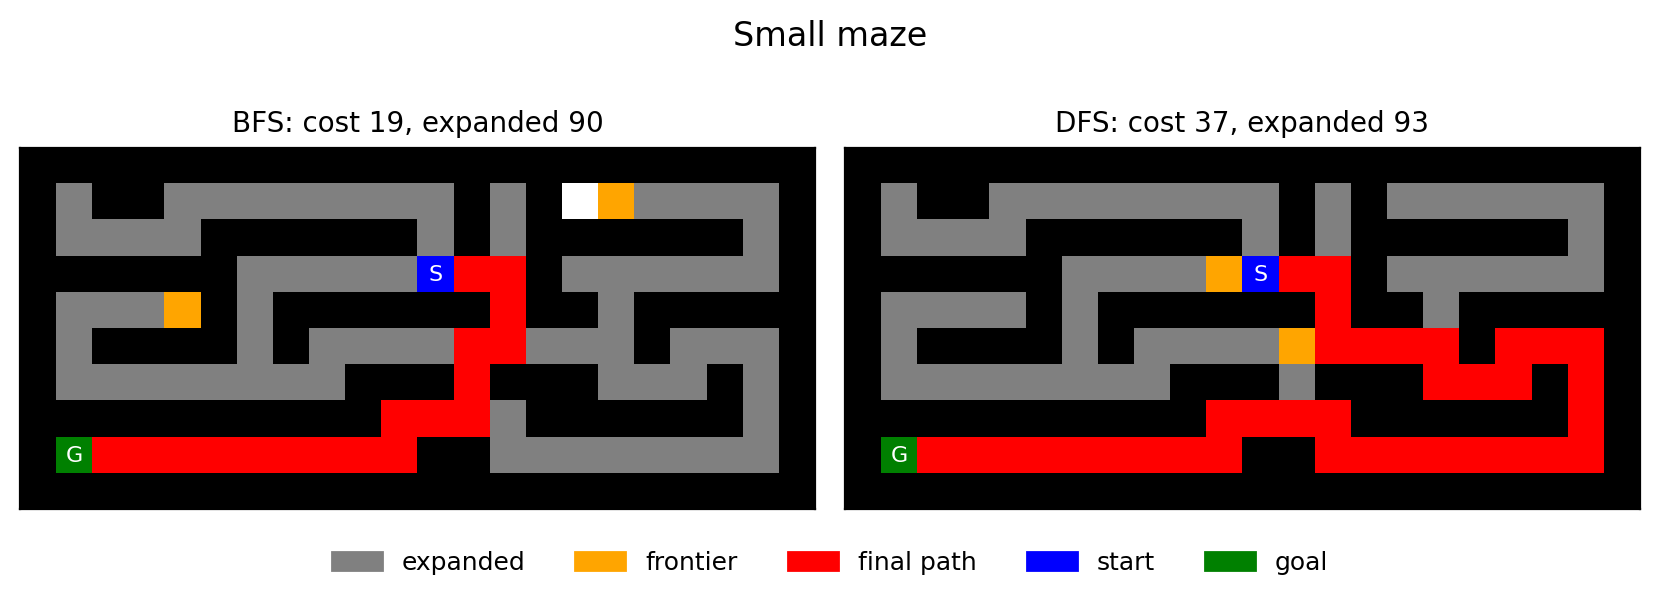

In [17]:
maze = mh.parse_maze(maze_str)                       # small maze from above
start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")

print("Plan (BFS):", "".join(plan_bfs(maze, start, goal)))
plot_results(maze, {"BFS": bfs(maze, start, goal), "DFS": dfs(maze, start, goal)}, "Small maze")

How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

**Loops and redundant paths**

* **BFS** has a `reached` set: a state gets a node only the first time it is generated, and the first time is also the shallowest one. A second path to the same square is simply ignored. This removes cycles *and* all other redundant paths, so BFS never goes in circles and expands every square at most once (e.g., 90 expansions on the small maze, which has 94 free squares).
* **DFS** has no `reached` table (otherwise it would need $O(n)$ memory like BFS). The only protection is the **cycle check**: a child is dropped if its state is already on the path from the root. This guarantees that every path is finite, so DFS cannot run forever on a finite maze, but it does **not** remove redundant paths (the same square reached by different paths). In corridors there are hardly any, but in **open spaces** the number of different simple paths is exponential. In the open maze, DFS (order N, E, S, W) had not found the goal after 1,000,000 expansions, while it needs only a few hundred expansions in the corridor mazes. See the experiment with different action orders in Task 4.

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

**Complete and optimal?**

| | complete | optimal | time | space |
|---|---|---|---|---|
| **BFS** (with `reached`) | yes: the state space is finite and every state is added only once, so it terminates and finds a goal if one is reachable | yes: the step cost is constant (1) and nodes are expanded by increasing depth, so the first goal found is the shallowest = cheapest | $O(b^d)$; with the `reached` table never more than $O(n)$ since every square is expanded at most once | $O(b^d)$, at most $O(n)$: all generated nodes are kept |
| **DFS** (cycle check only) | yes in theory (all paths are finite on a finite maze) but not in practice: it can need exponentially long in open spaces (hence my safety limit) | **no**: it returns the first goal it meets, not the cheapest | $O(b^m)$ with $m \le n$ | $O(bm)$: the current path plus the unexplored siblings |

**Time and space in my experiments.** BFS keeps all generated nodes: 93 nodes on the small maze and 622 on the large maze, while DFS needed only 48 and 255. This is the advantage of DFS: memory grows with the depth of the current path, not with the number of squares. The price is the solution quality (cost 37 instead of 19 on the small maze, 244 instead of 68 on the medium maze) and the risk of exponential time. The memory advantage is also **not guaranteed**: when the DFS tree gets deep, $O(bm)$ can be larger than BFS's $O(n)$ (open maze: DFS already held 1099 nodes when it was stopped, BFS needs 683).

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

Both algorithms are best-first search with a priority queue ordered by an evaluation function $f(n)$: $f(n) = h(n)$ for greedy best-first search (GBFS) and $f(n) = g(n) + h(n)$ for A*. The heuristic $h$ is the Manhattan distance to the closest goal. Compared to BFS the FIFO queue is replaced by a priority queue (`heapq`), the goal test is done when a node is taken from the frontier (needed for the optimality of A*), and a state is re-added if a cheaper path to it is found. Equal priorities are served first-in-first-out.

In [9]:
def manhattan(pos, goals):
    """Manhattan distance to the closest goal (admissible and consistent for 4-neighbour moves)."""
    return min(abs(pos[0] - g[0]) + abs(pos[1] - g[1]) for g in goals)

def best_first(maze, start, goal, f):
    """Best-first search (graph search with `reached`). f(node) is the evaluation function:
    f = h for greedy best-first search and f = g + h for A*."""
    start, goals = as_pos(start), as_goal_set(goal)
    root = Node(start, None, None, 0)
    tie = itertools.count()                            # tie-breaker: first in, first out
    frontier = [(f(root, goals), next(tie), root)]     # priority queue
    reached = {start: root}                            # best node found so far for every state
    expanded, max_depth, max_frontier, n_created = 0, 0, 1, 1
    visited = set()

    while frontier:
        _, _, node = heapq.heappop(frontier)
        if node.pos in goals:                          # late goal test (needed for A* optimality)
            return make_result(node, "solution", expanded, max_depth, max_frontier, n_created,
                               visited, [n.pos for _, _, n in frontier])
        if reached[node.pos] is not node:              # outdated node (a cheaper path was found later)
            continue
        expanded += 1
        visited.add(node.pos)
        for child in expand(maze, node):
            if child.pos not in reached or child.cost < reached[child.pos].cost:
                reached[child.pos] = child
                heapq.heappush(frontier, (f(child, goals), next(tie), child))
                n_created += 1
                max_depth = max(max_depth, child.cost)
                max_frontier = max(max_frontier, len(frontier))
    return make_result(None, "failure", expanded, max_depth, max_frontier, n_created, visited, [])

def gbfs(maze, start, goal):
    """Greedy best-first search: f(n) = h(n)."""
    return best_first(maze, start, goal, f=lambda n, goals: manhattan(n.pos, goals))

def astar(maze, start, goal):
    """A* search: f(n) = g(n) + h(n)."""
    return best_first(maze, start, goal, f=lambda n, goals: n.cost + manhattan(n.pos, goals))

def plan_gbfs(maze, start, goal):
    return gbfs(maze, start, goal)["actions"]

def plan_astar(maze, start, goal):
    return astar(maze, start, goal)["actions"]

Plan (A*): EESSWSSWWSWWWWWWWWW


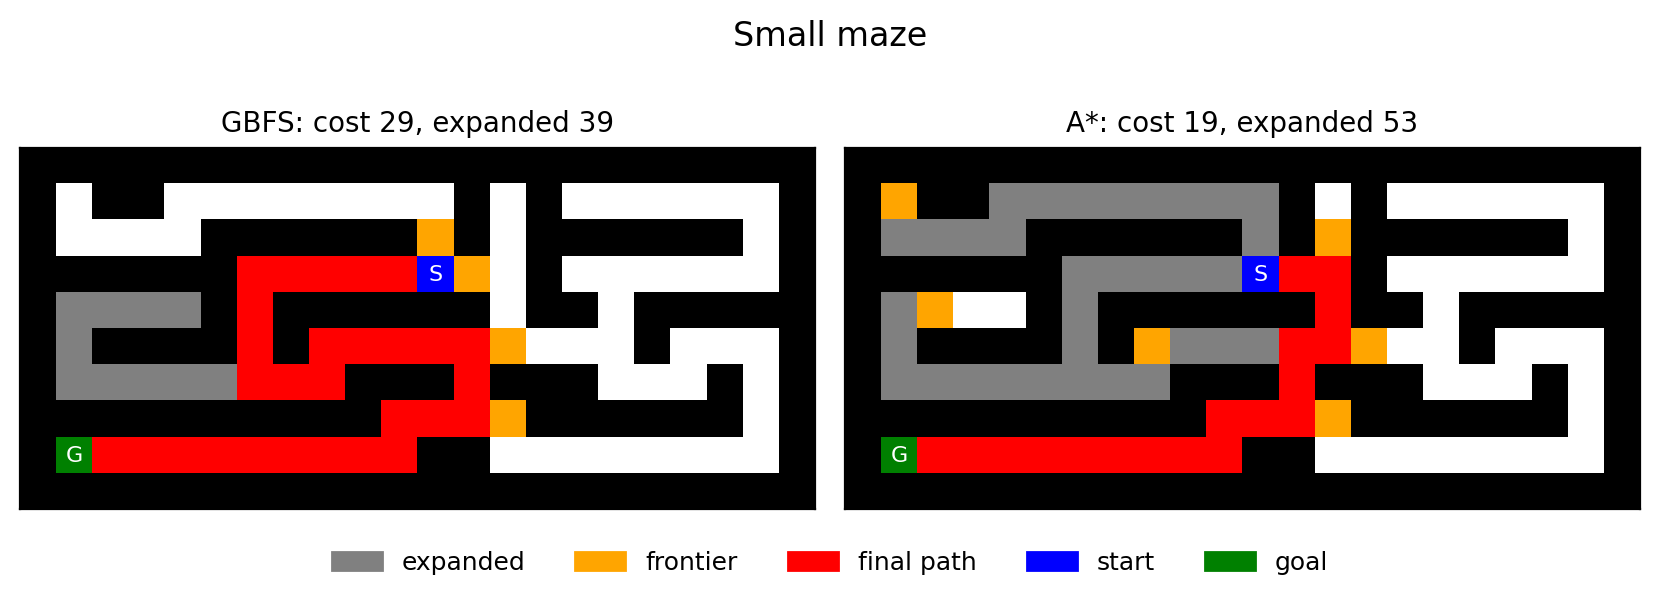

In [19]:
print("Plan (A*):", "".join(plan_astar(maze, start, goal)))
plot_results(maze, {"GBFS": gbfs(maze, start, goal), "A*": astar(maze, start, goal)}, "Small maze")

Are your implementations complete and optimal? What is the time and space complexity?

**Heuristic.** The Manhattan distance is **admissible** (every step moves one square, so at least $|{\Delta r}| + |{\Delta c}|$ steps are needed; walls can only make the real path longer) and even **consistent** ($h(n) \le 1 + h(n')$ for every neighbour $n'$).

| | complete | optimal | time / space |
|---|---|---|---|
| **GBFS** | yes in a finite maze with a `reached` table (a state is never expanded twice) | **no**: it follows $h$ only and can be lured into a dead end close to the goal, e.g., cost 29 instead of 19 on the small maze and 68 instead of 54 on the open maze | worst case $O(b^m)$ in a tree search; with `reached` at most $O(n)$. In practice it often expands very few nodes (open maze: 89 vs. 679 for BFS) |
| **A\*** | yes | **yes**, because $h$ is admissible (and consistent, so the first time a state is expanded its path is optimal). The costs equal the BFS costs in all mazes | worst case exponential in the error of the heuristic, at most $O(n)$ with `reached`; all generated nodes stay in memory. It expanded fewer nodes than BFS in every maze (e.g., 53 vs. 146 in the L maze) |

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

All mazes are loaded and every algorithm is run once per maze. DFS gets a safety limit of 1,000,000 expansions (`MAX_EXPANSIONS`); a run that hits the limit is reported as **N/A\***.

In [16]:
MAX_EXPANSIONS = 1_000_000          # safety limit for DFS (and IDS) in open spaces

algorithms = {"BFS": bfs,
              "DFS": lambda m, s, g: dfs(m, s, g, max_expansions=MAX_EXPANSIONS),
              "GBFS": gbfs,
              "A*": astar}

results = {}                         # results[maze name][algorithm name] -> result dictionary
for name, maze in mazes.items():
    start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
    results[name] = {alg: fn(maze, start, goal) for alg, fn in algorithms.items()}

**Solutions.** Every picture shows the squares expanded by the algorithm (gray), the squares still on the frontier when the search stopped (orange) and the final path (red).

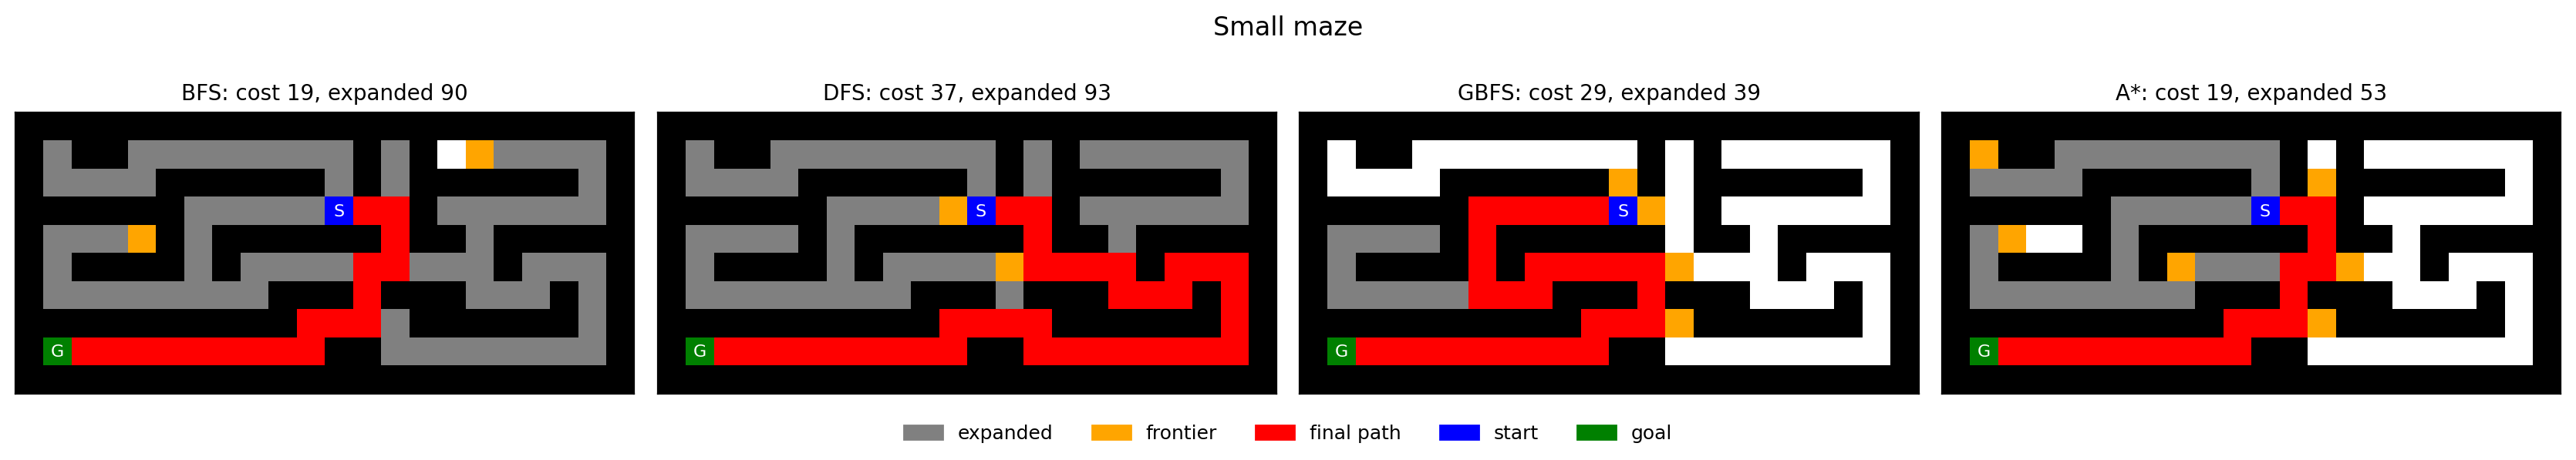

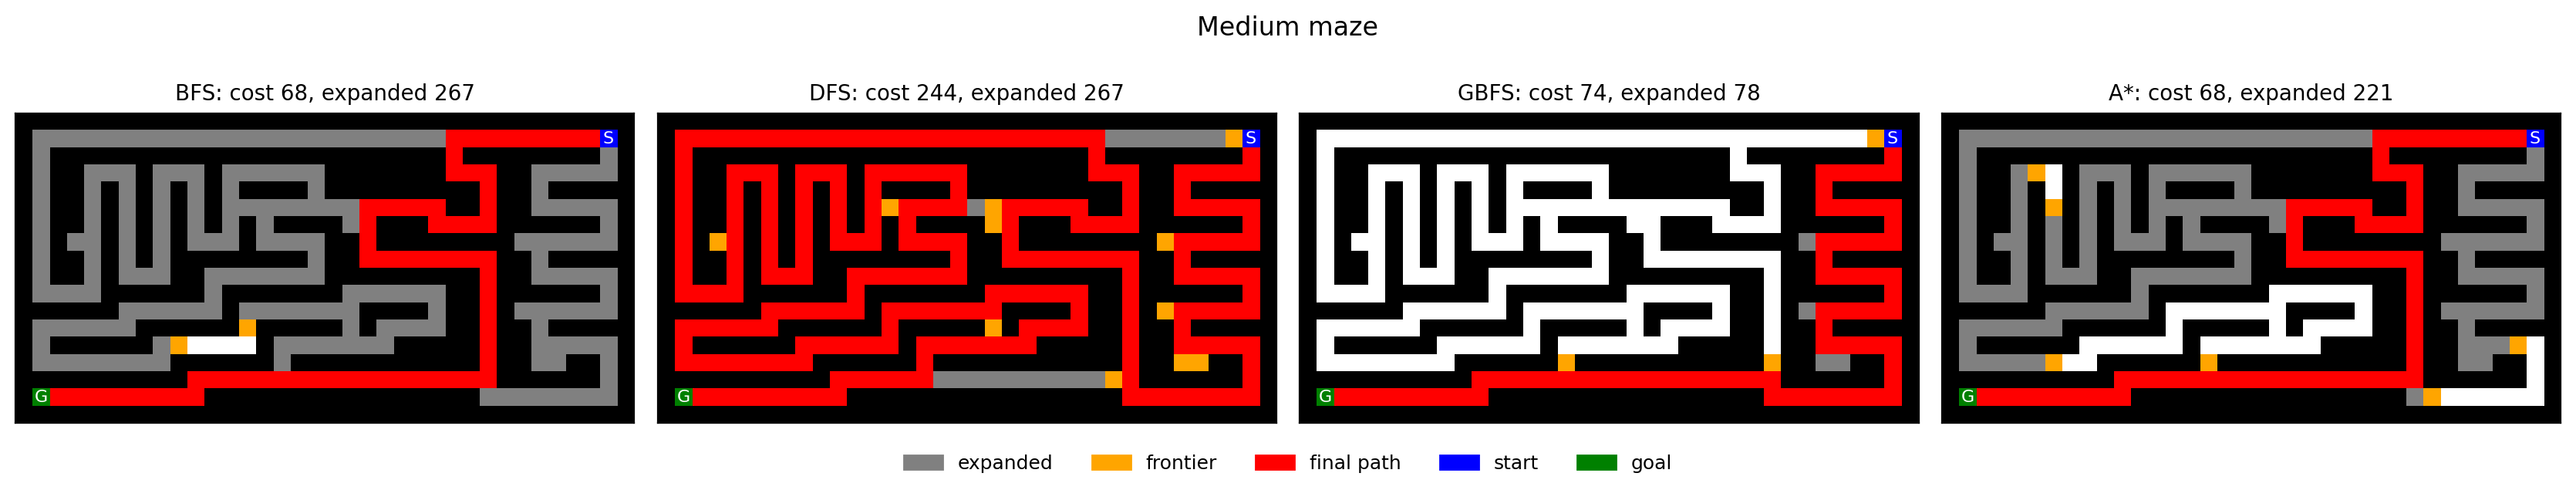

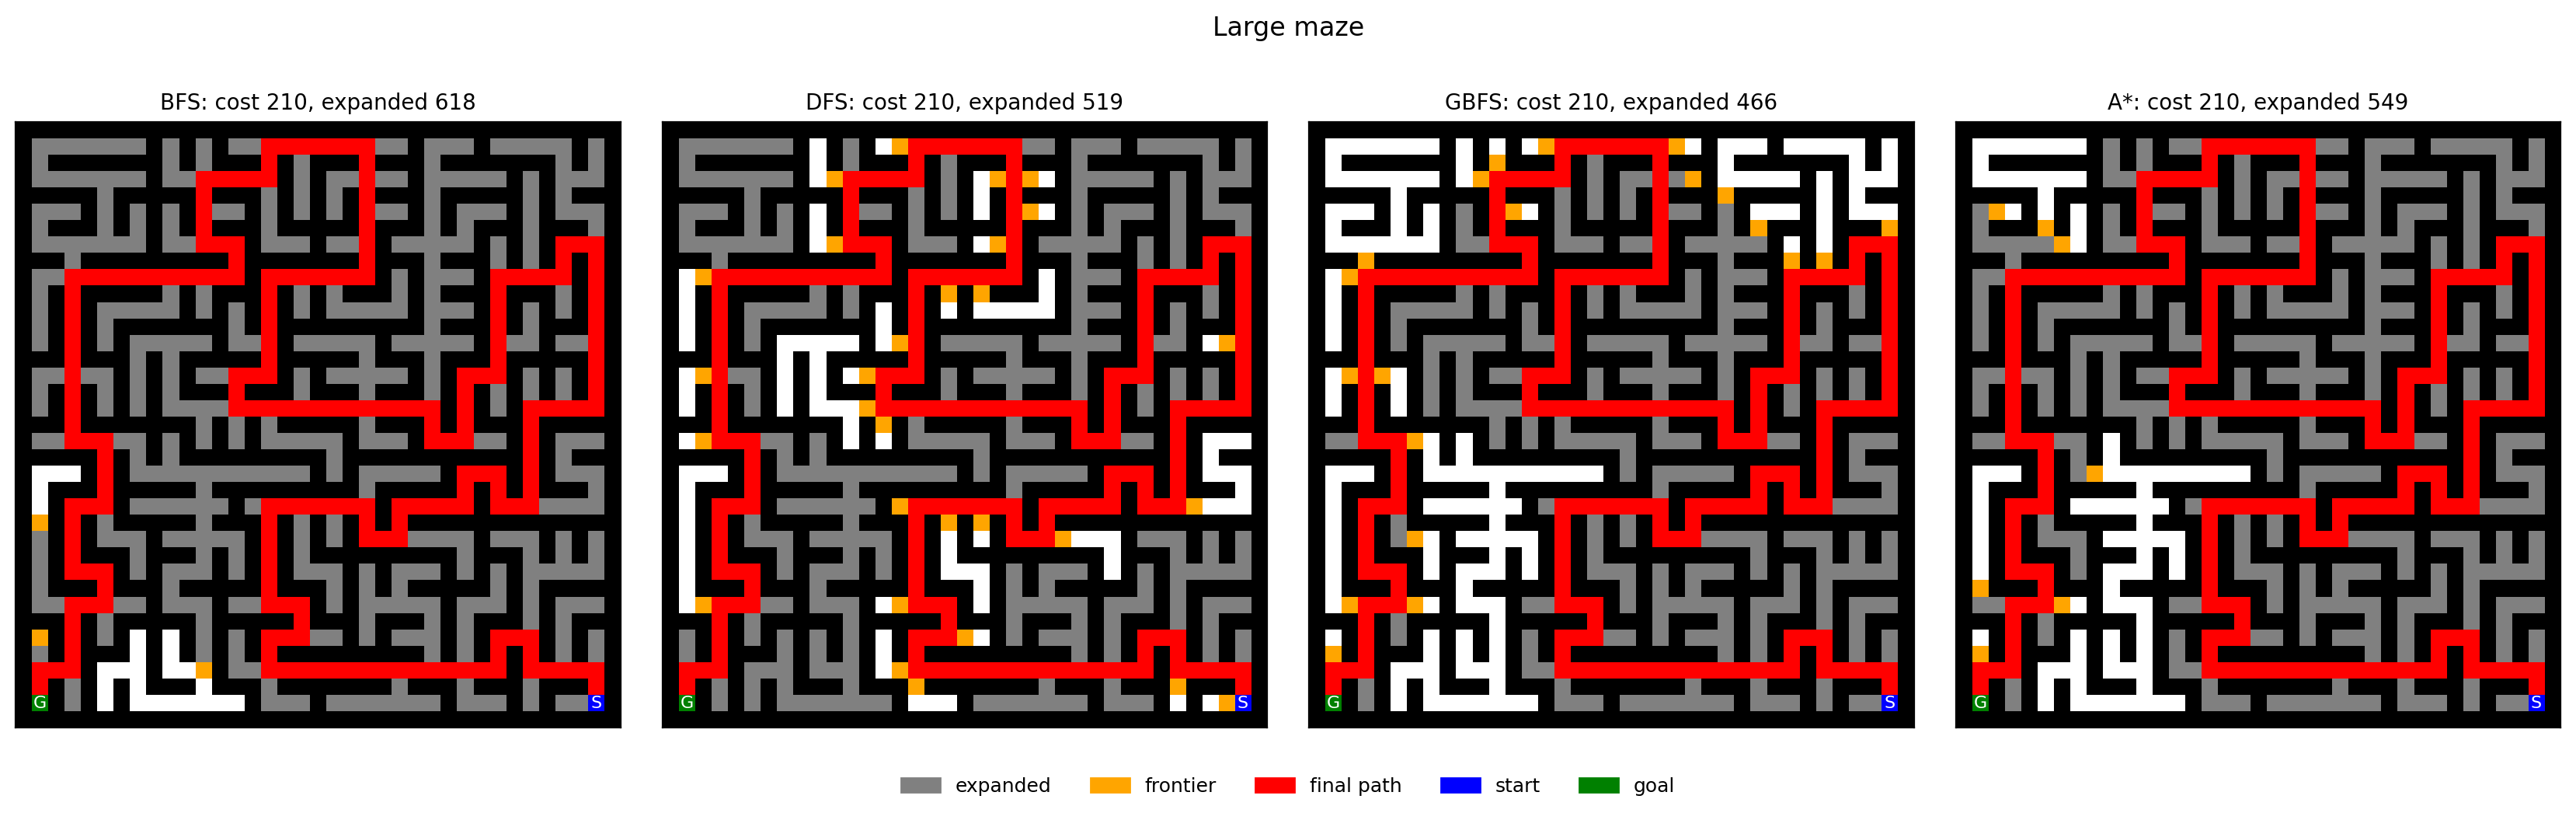

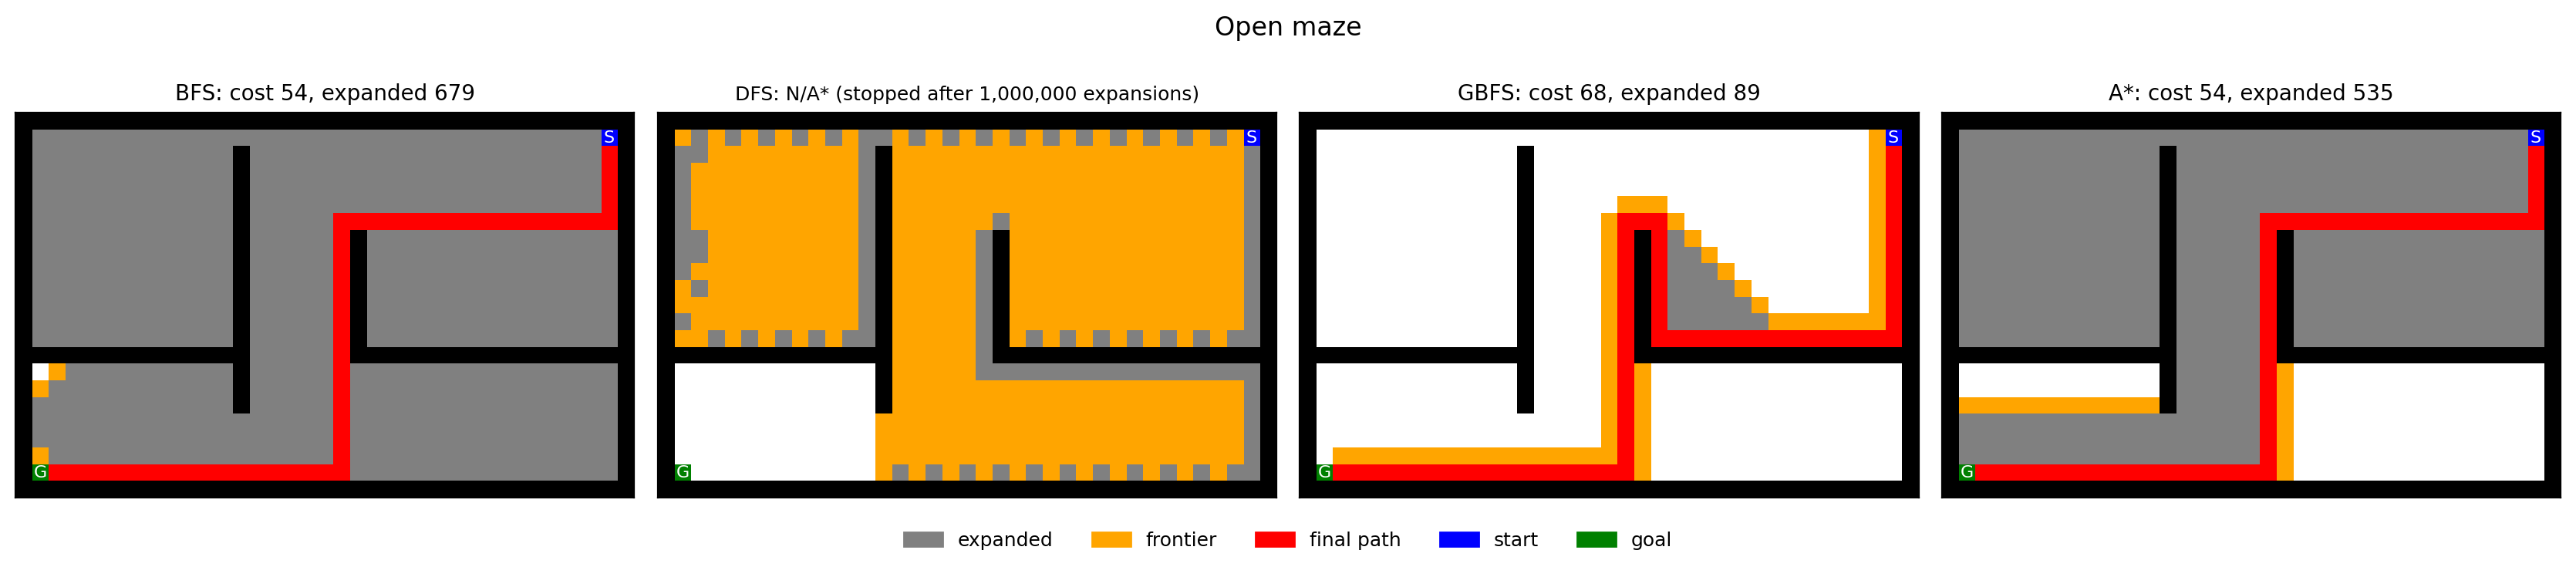

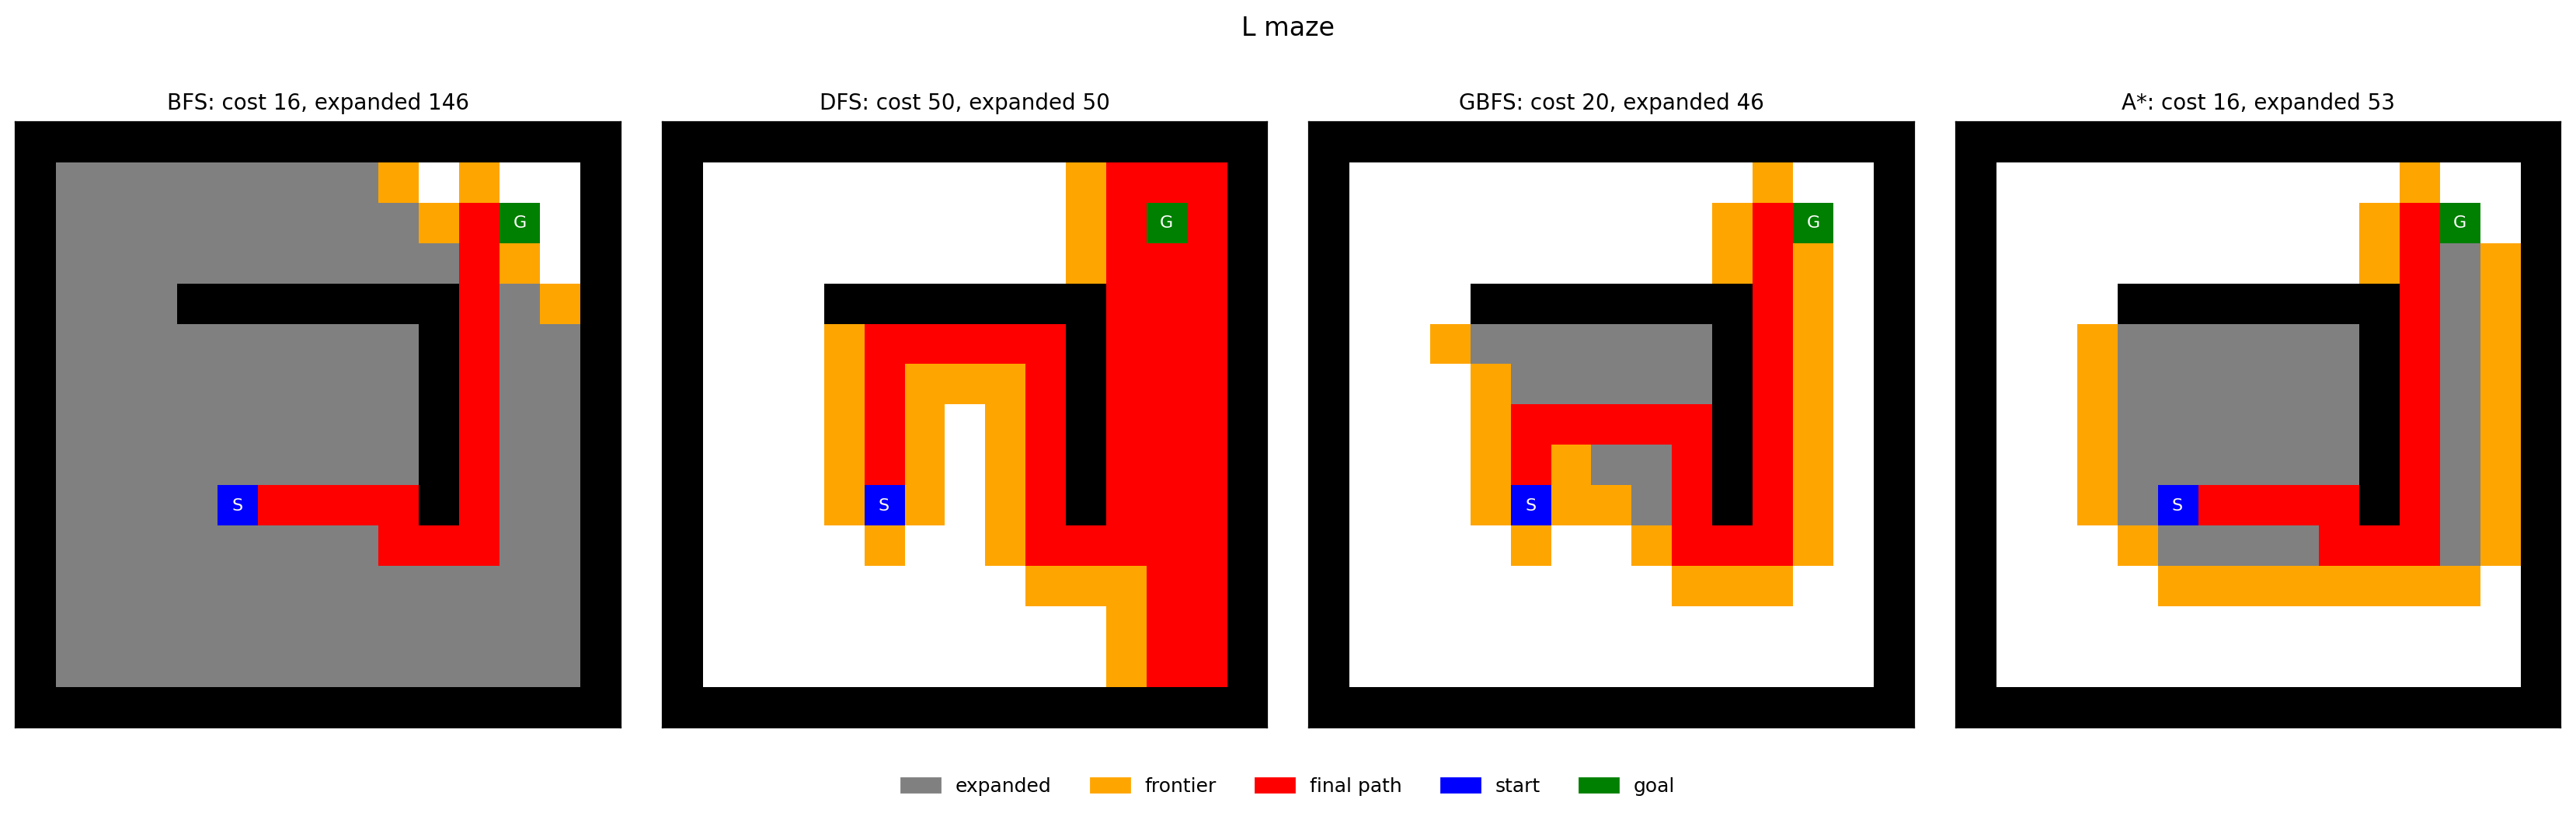

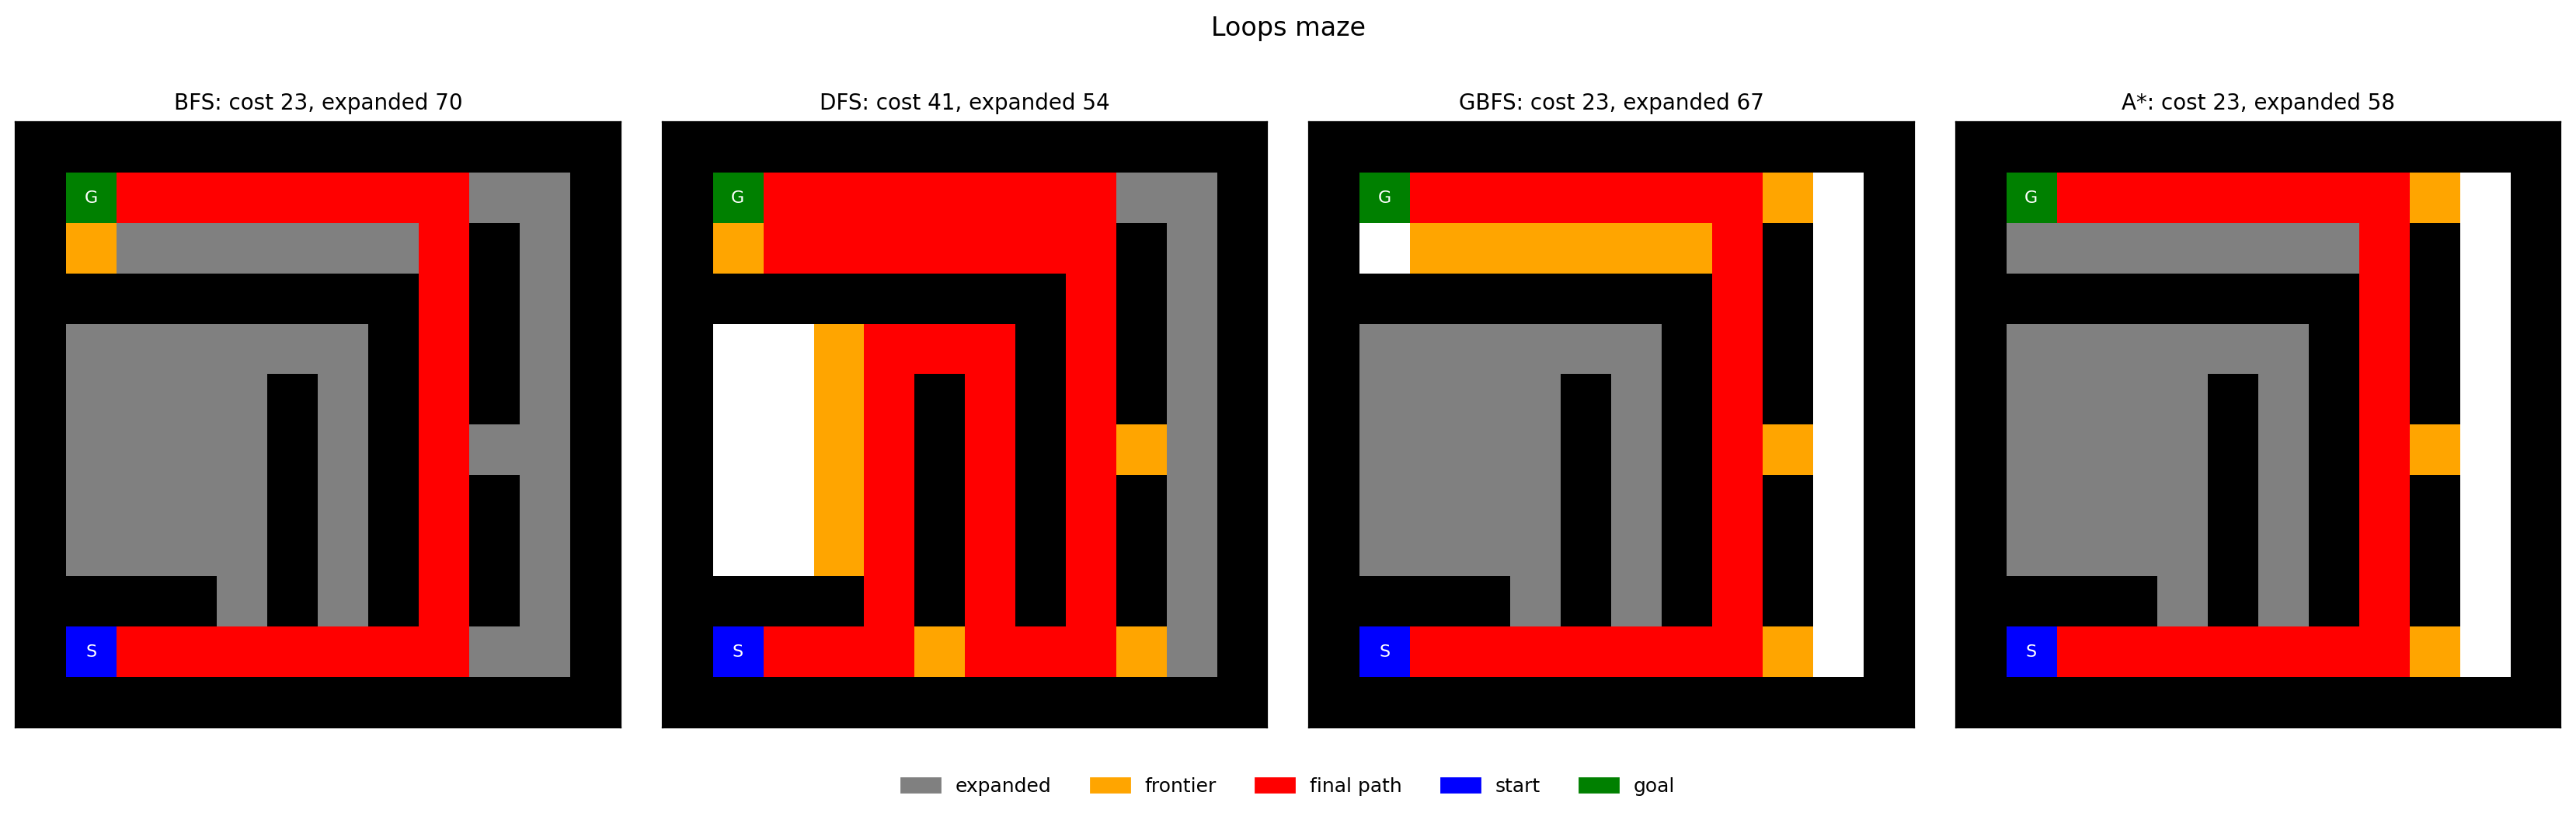

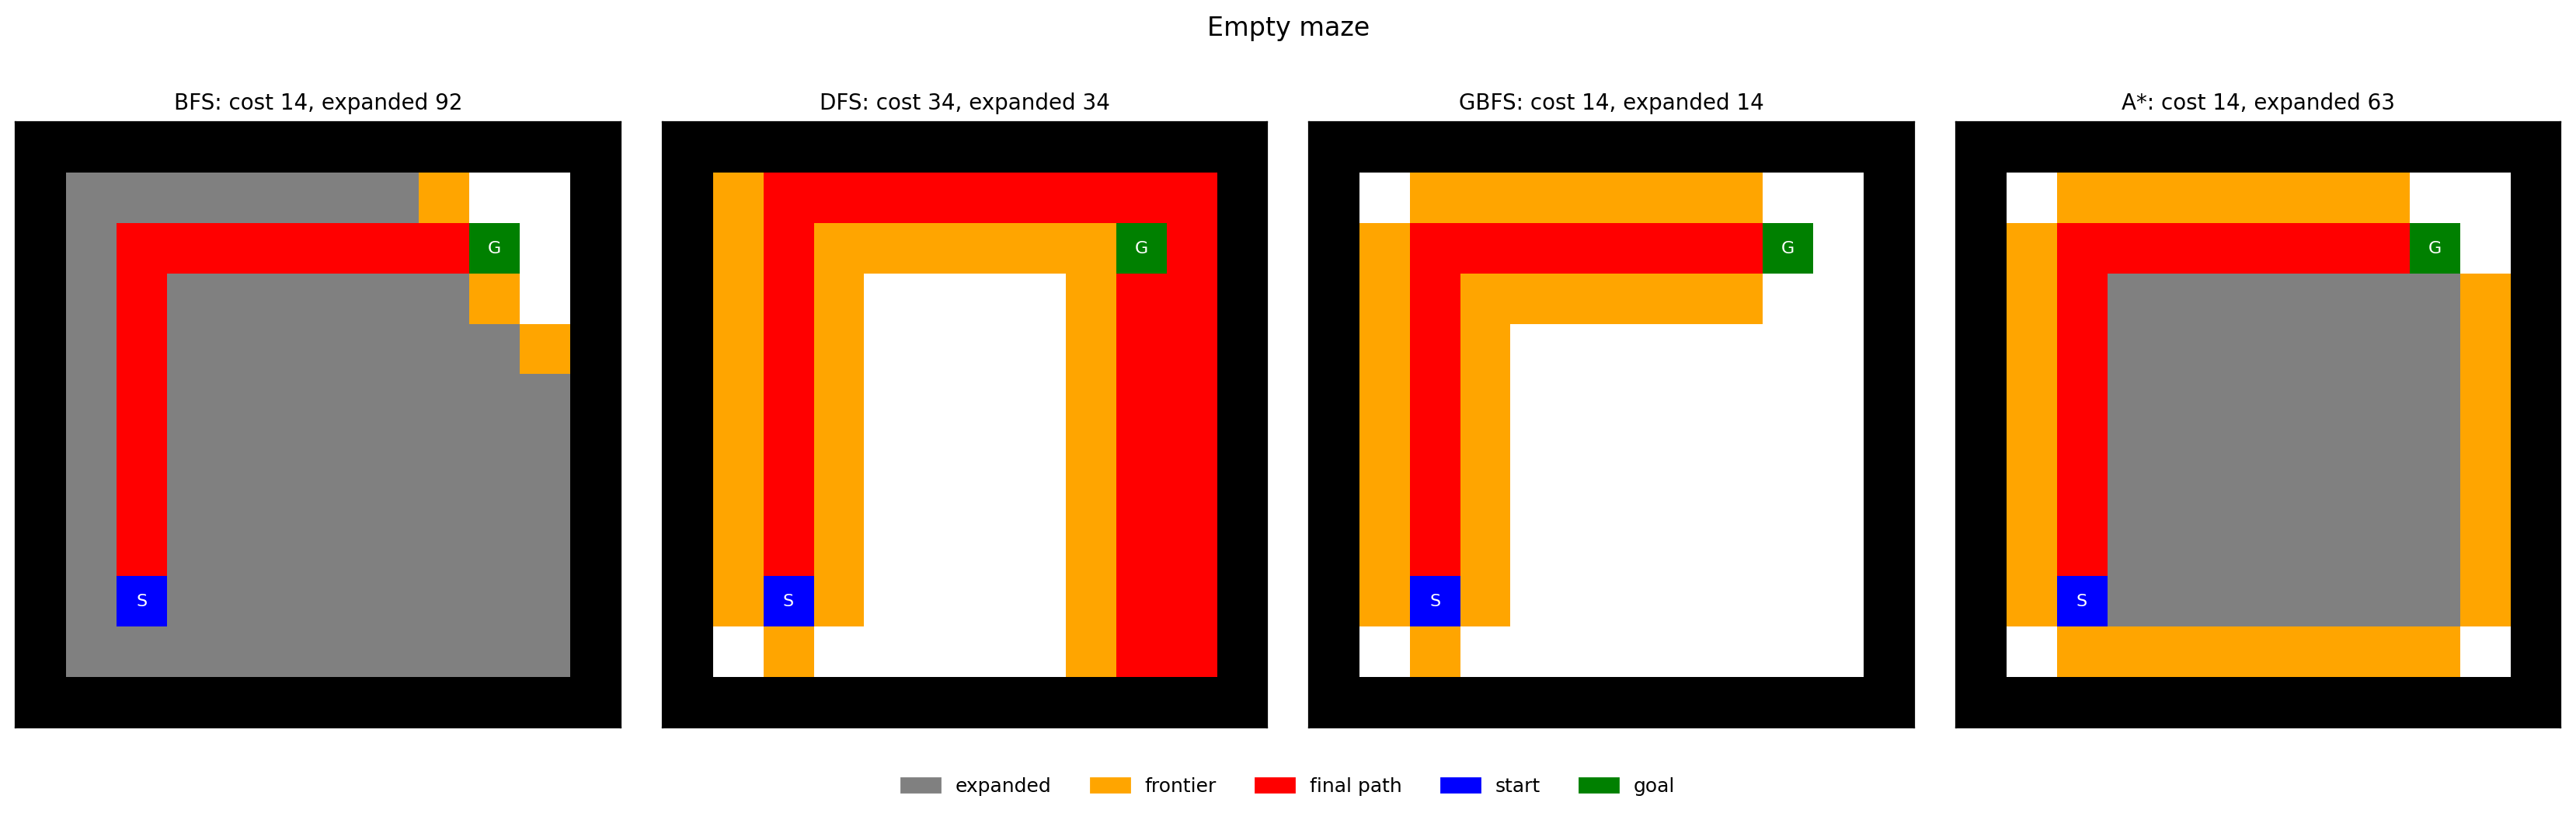

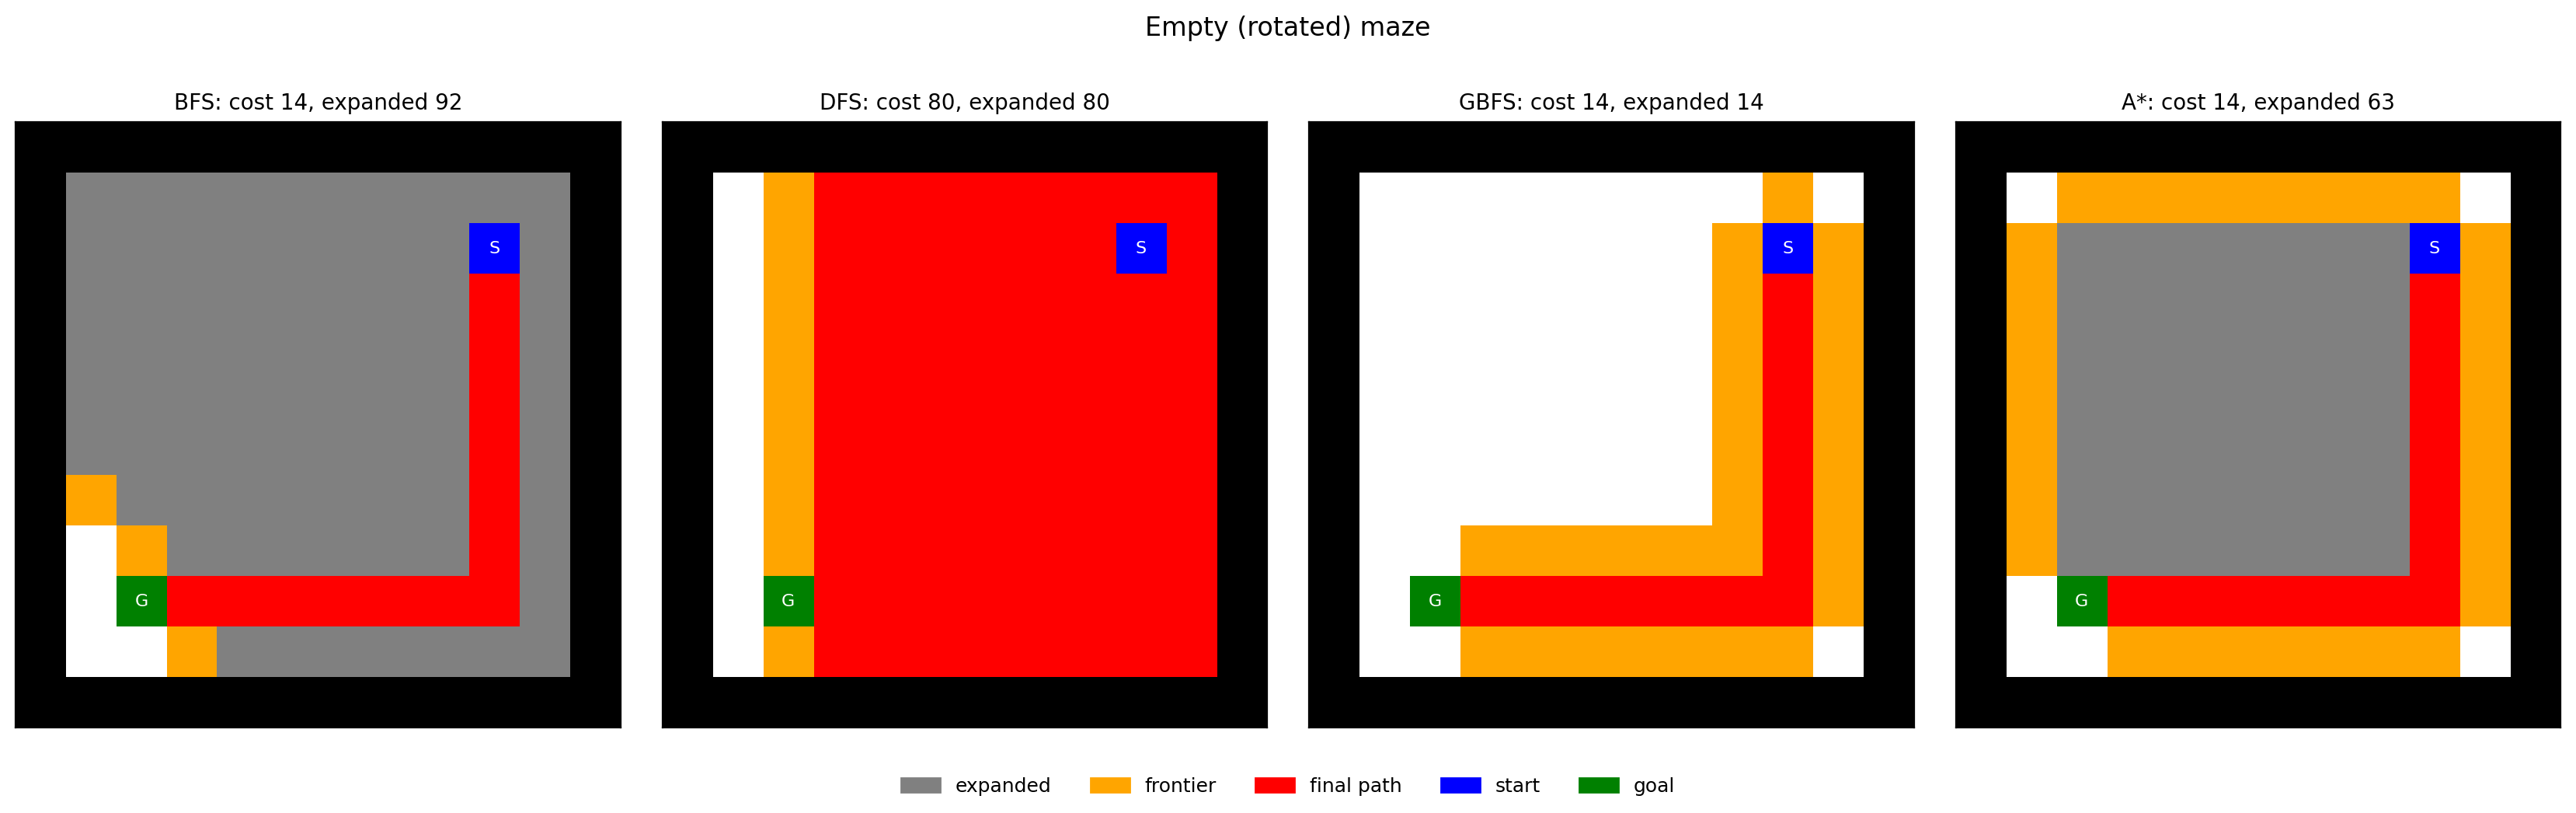

In [21]:
for name, maze in mazes.items():
    plot_results(maze, results[name], f"{name.capitalize()} maze")

In [17]:
import time

def run_timed(fn, maze, start, goal):
    """Run a search function and store the running time (in seconds) in the result."""
    t0 = time.perf_counter()
    res = fn(maze, start, goal)
    res["time"] = time.perf_counter() - t0
    return res

results = {}                         # results[maze name][algorithm name] -> result dictionary
for name, maze in mazes.items():
    start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
    results[name] = {alg: run_timed(fn, maze, start, goal) for alg, fn in algorithms.items()}

**Results tables** (one table per maze, as required):

In [19]:
def val(res, key):
    return str(res[key]) if res["status"] == "solution" else "N/A*"

def time_val(res):
    """Running time in seconds; for a stopped run (N/A*) show the time until it was stopped."""
    return f"{res['time']:.4f}" if res["status"] == "solution" else f"N/A* (stopped after {res['time']:.1f})"

headers = ["Algorithm", "Path cost", "# of nodes expanded", "Max tree depth", "Max frontier size", "Time (s)"]
for name in mazes:
    rows = [[alg, val(r, "cost"), val(r, "expanded"), val(r, "max_depth"), val(r, "max_frontier"), time_val(r)]
            for alg, r in results[name].items()]
    display(Markdown(f"__{name.capitalize()} maze__\n\n" + md_table(headers, rows)))

failed = [(n, a, r["expanded"]) for n in results for a, r in results[n].items() if r["status"] != "solution"]
for n, a, e in failed:
    display(Markdown(f"\\* **N/A\\***: {a} on the {n} maze did not find the goal within the limit of {e:,} node expansions "
                     "(it is not a bug of the code, see the discussion of cycle checking above)."))

__Small maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 19 | 90 | 19 | 9 | 0.0005 |
| DFS | 37 | 93 | 44 | 5 | 0.0006 |
| GBFS | 29 | 39 | 29 | 5 | 0.0002 |
| A* | 19 | 53 | 19 | 8 | 0.0007 |

__Medium maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 68 | 267 | 68 | 9 | 0.0013 |
| DFS | 244 | 267 | 244 | 14 | 0.0041 |
| GBFS | 74 | 78 | 74 | 4 | 0.0006 |
| A* | 68 | 221 | 68 | 8 | 0.0016 |

__Large maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 210 | 618 | 210 | 8 | 0.0031 |
| DFS | 210 | 519 | 222 | 34 | 0.0060 |
| GBFS | 210 | 466 | 210 | 21 | 0.0027 |
| A* | 210 | 549 | 210 | 12 | 0.0032 |

__Open maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 54 | 679 | 54 | 25 | 0.0036 |
| DFS | N/A* | N/A* | N/A* | N/A* | N/A* (stopped after 38.9) |
| GBFS | 68 | 89 | 68 | 66 | 0.0007 |
| A* | 54 | 535 | 54 | 25 | 0.0035 |

__L maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 16 | 146 | 16 | 17 | 0.0008 |
| DFS | 50 | 50 | 50 | 49 | 0.0004 |
| GBFS | 20 | 46 | 20 | 25 | 0.0003 |
| A* | 16 | 53 | 16 | 26 | 0.0004 |

__Loops maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 23 | 70 | 23 | 8 | 0.0004 |
| DFS | 41 | 54 | 41 | 17 | 0.0004 |
| GBFS | 23 | 67 | 23 | 10 | 0.0004 |
| A* | 23 | 58 | 23 | 6 | 0.0003 |

__Empty maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 12 | 0.0005 |
| DFS | 34 | 34 | 34 | 42 | 0.0003 |
| GBFS | 14 | 14 | 14 | 29 | 0.0001 |
| A* | 14 | 63 | 14 | 31 | 0.0011 |

__Empty (rotated) maze__

| Algorithm | Path cost | # of nodes expanded | Max tree depth | Max frontier size | Time (s) |
|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 11 | 0.0006 |
| DFS | 80 | 80 | 80 | 73 | 0.0008 |
| GBFS | 14 | 14 | 14 | 29 | 0.0001 |
| A* | 14 | 63 | 14 | 31 | 0.0004 |

\* **N/A\***: DFS on the open maze did not find the goal within the limit of 1,000,000 node expansions (it is not a bug of the code, see the discussion of cycle checking above).

**Effect of the order of the actions on DFS (open maze).** DFS without a `reached` table depends on luck. I run it on the open maze with four different orders in which the children are generated (limit 200,000 expansions):

In [23]:
open_maze = mazes["open"]
s_open, g_open = mh.find_pos(open_maze, "S"), mh.find_pos(open_maze, "G")
rows = []
saved_order = list(ACTION_ORDER)
for order in (["N", "E", "S", "W"], ["E", "S", "W", "N"], ["S", "W", "E", "N"], ["W", "S", "E", "N"]):
    ACTION_ORDER[:] = order
    r = dfs(open_maze, s_open, g_open, max_expansions=200_000)
    rows.append([", ".join(order), val(r, "cost"), f"{r['expanded']:,}" if r["status"] == "solution" else "N/A* (limit reached)"])
ACTION_ORDER[:] = saved_order                       # restore the default order
display(Markdown(md_table(["order of children", "path cost", "# of nodes expanded"], rows)))

| order of children | path cost | # of nodes expanded |
|---|---|---|
| N, E, S, W | N/A* | N/A* (limit reached) |
| E, S, W, N | 206 | 206 |
| S, W, E, N | 146 | 146 |
| W, S, E, N | N/A* | N/A* (limit reached) |

The tables above are generated by the code (they replace the empty template tables). The same results as charts:

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

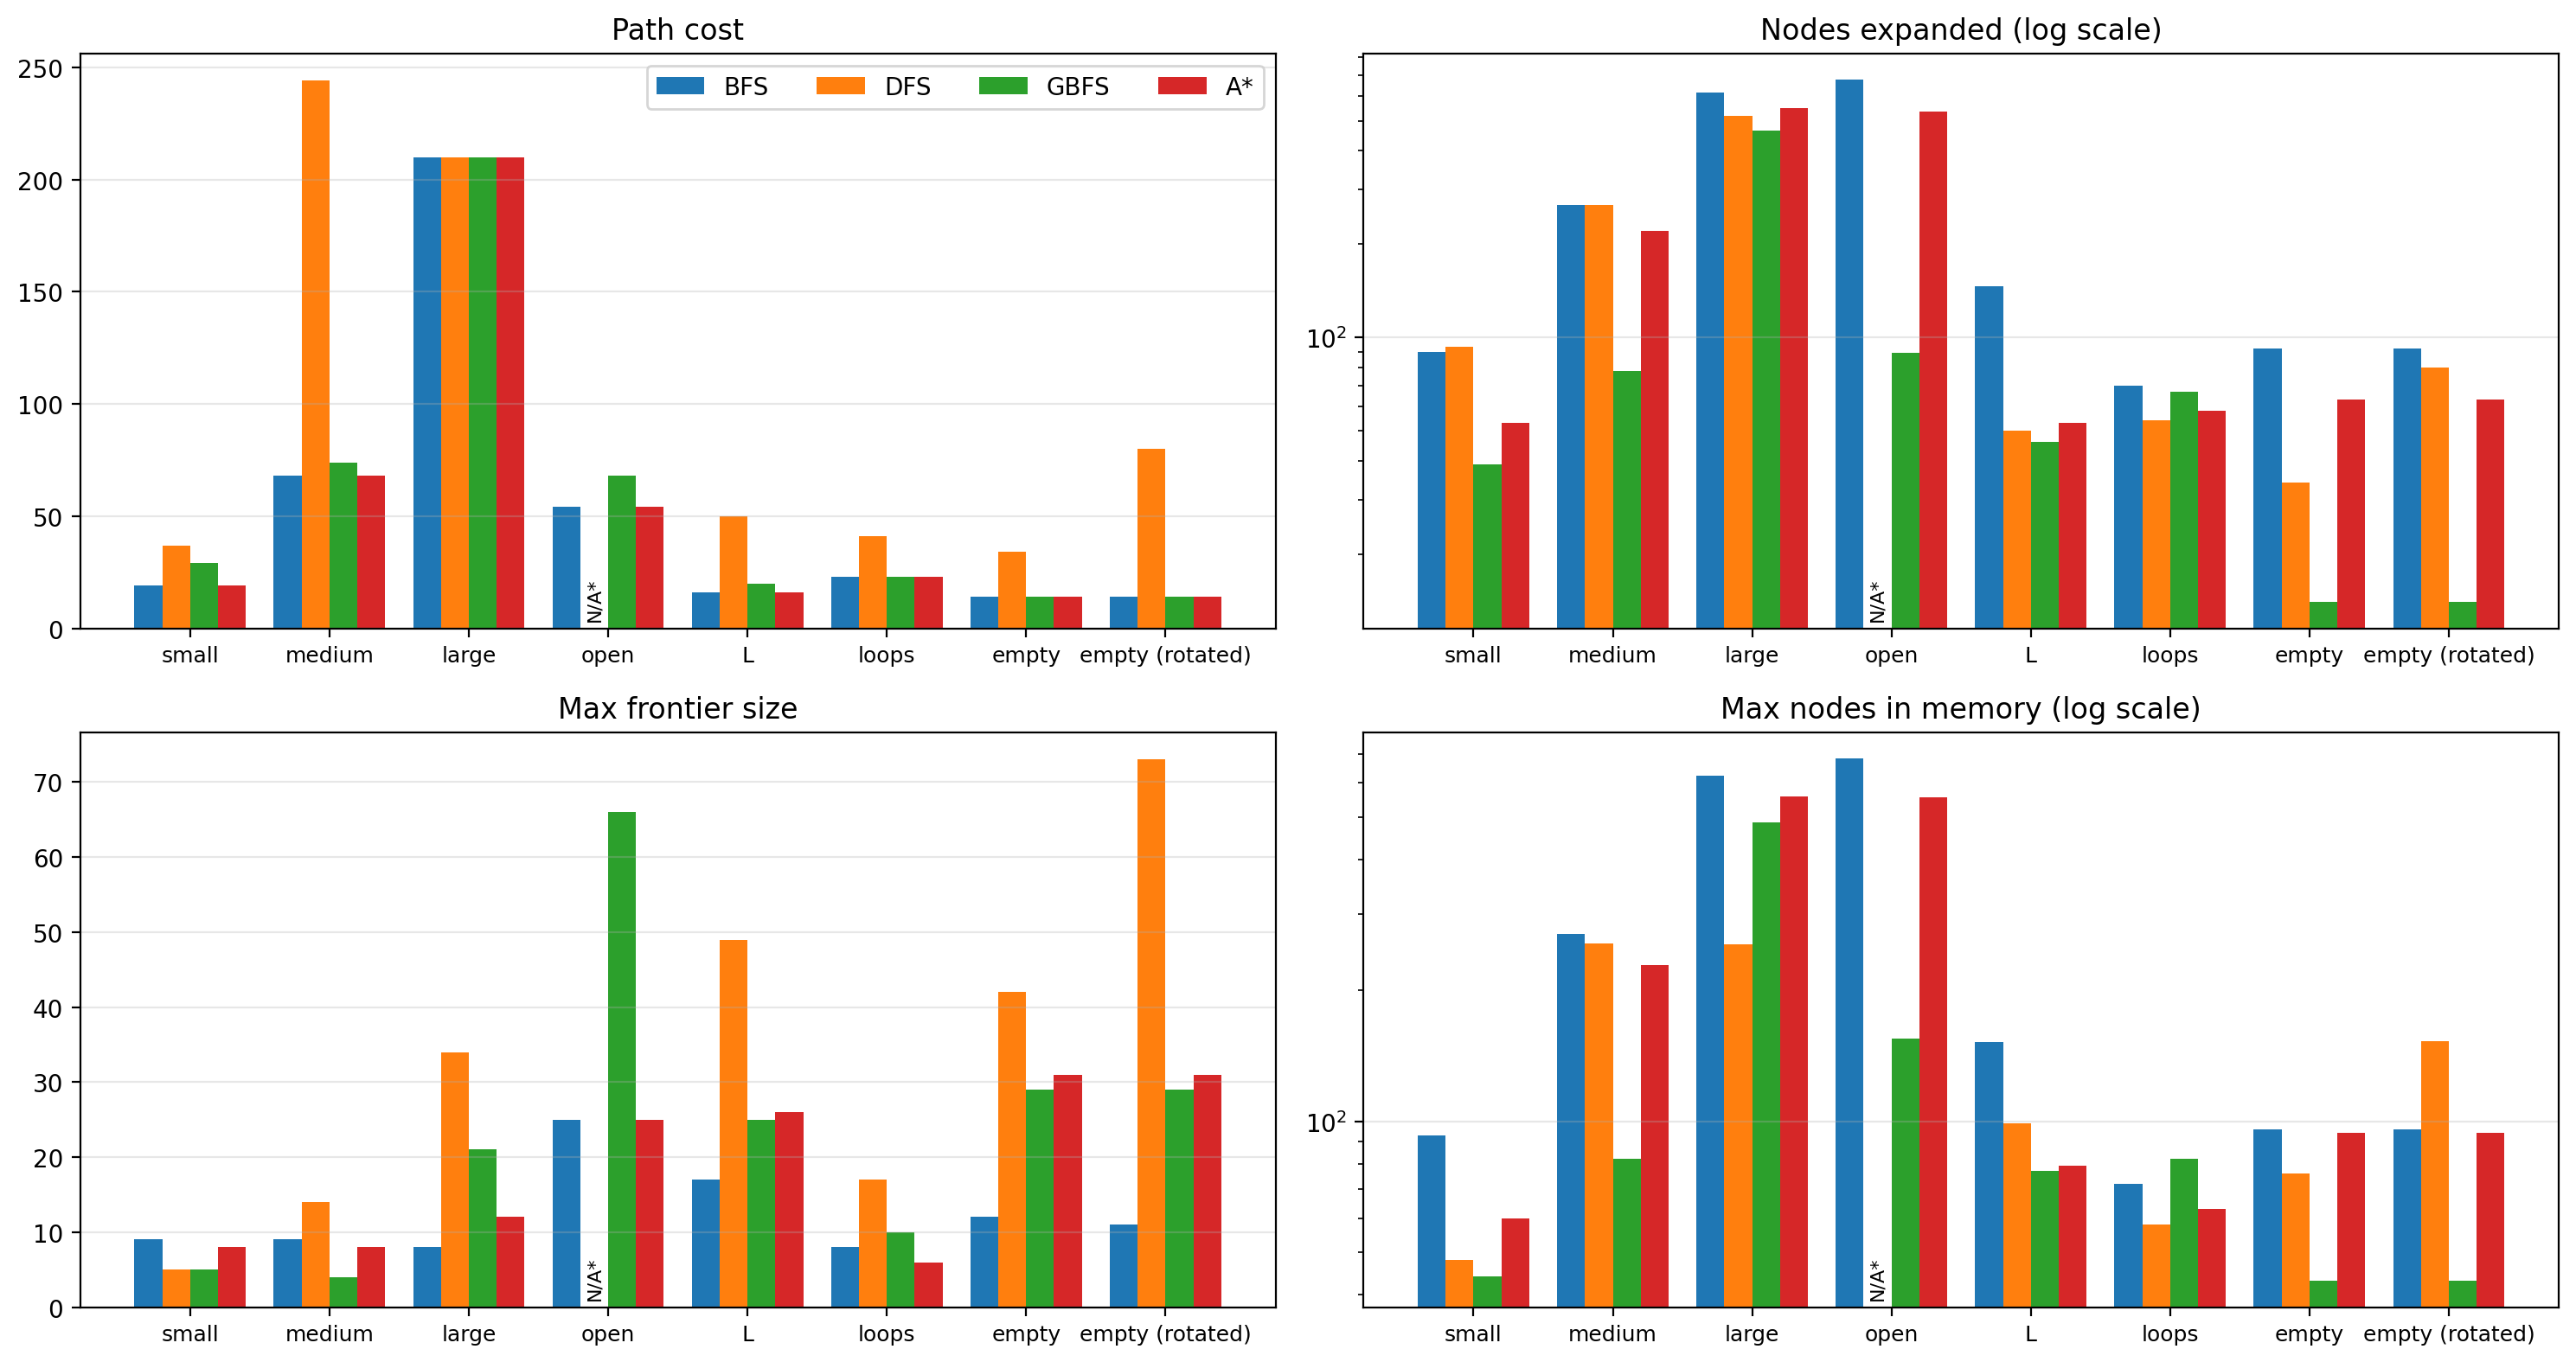

In [24]:
algs, names = list(algorithms), list(mazes)
metrics = [("cost", "Path cost", False), ("expanded", "Nodes expanded", True),
           ("max_frontier", "Max frontier size", False), ("max_memory", "Max nodes in memory", True)]
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
w = 0.2
for ax, (key, title, log) in zip(axes.ravel(), metrics):
    for i, alg in enumerate(algs):
        vals = [results[n][alg][key] if results[n][alg]["status"] == "solution" else np.nan for n in names]
        x = np.arange(len(names)) + (i - 1.5) * w
        ax.bar(x, vals, w, label=alg)
        for xi, vi in zip(x, vals):
            if np.isnan(vi):                              # mark runs without result
                ax.annotate("N/A*", (xi, 0), xycoords=("data", "axes fraction"), xytext=(0, 3),
                            textcoords="offset points", rotation=90, ha="center", va="bottom", fontsize=8)
    if log: ax.set_yscale("log")
    ax.set_xticks(np.arange(len(names))); ax.set_xticklabels(names, fontsize=9)
    ax.set_title(title + (" (log scale)" if log else ""))
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].legend(ncol=4)
fig.tight_layout()
plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies. 

**Most important lessons**

1. **BFS and A\* are optimal, DFS and GBFS are not.** BFS and A* returned the same (optimal) cost in all 8 mazes (19, 68, 210, 54, 16, 23, 14, 14). DFS found a path in 7 of the 8 mazes but it was longer than the optimum in 6 of them (e.g., 244 steps instead of 68 in the medium maze, 80 instead of 14 in the rotated empty maze). It was optimal only in the large maze, whose corridors leave hardly any alternative. GBFS was longer than optimal in 4 mazes (small, medium, open, L).
2. **The heuristic saves work.** A* expanded fewer nodes than BFS in every maze (open maze: 535 vs. 679, L maze: 53 vs. 146) and still found the optimal path. The saving is small in the corridor mazes (medium: 221 vs. 267) because the walls force the path away from the straight line to the goal and the Manhattan distance is then not informative. GBFS expanded even fewer nodes in most mazes (open maze: only 89), but pays with solution quality.
3. **Without a `reached` table, open spaces are dangerous.** DFS with only a cycle check explores a huge number of redundant paths in open areas. In the open maze it was stopped after 1,000,000 expansions (N/A\*), and the action-order experiment shows that it only succeeds by luck. BFS, GBFS and A* solve the same maze in under 700 expansions. Cycle checking removes infinite loops, not redundant paths.
4. **Memory: tree search with DFS is cheap, graph search is expensive.** BFS, GBFS and A* keep every generated node (memory $\approx$ number of reached squares, e.g., 622 nodes in the large maze), DFS only needs the current path and its siblings (255). The advantage depends on the maze: in the medium maze it is small (257 vs. 270) because the DFS path itself is almost as long as the maze, and in the rotated empty maze DFS needed more memory than BFS (153 vs. 96) because its depth (80) is much larger than $d$ (14).
5. **The frontier of BFS stays small in corridors** (at most 9 nodes in the corridor mazes) **but grows in open areas** (25 in the open maze). DFS often has the largest frontier in open mazes (up to 73 in the rotated empty maze) because it stores the siblings of every node on its long path.
6. **The right choice depends on the goal:** BFS/A* if the cost matters (A* is the better one if a good heuristic exists), GBFS if a fast, "good enough" plan is enough, DFS only if memory is the bottleneck and the state space has no large open areas.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

Iterative deepening search (IDS) calls the depth-limited version of my DFS (`dfs(..., depth_limit=l)`, with cycle checking, no `reached` table) with $l = 0, 1, 2, \dots$ until a goal is found. Total expansions are summed over all iterations. If an iteration ends without a cutoff the maze has no solution. The same safety limit as for DFS is used for the total number of expansions.

In [25]:
def ids(maze, start, goal, max_expansions=None):
    """Iterative deepening search: depth-limited DFS (with cycle checking) with limit 0, 1, 2, ...
    max_expansions is a budget for the total number of expansions over all iterations."""
    total, max_depth, max_frontier, max_memory, limit = 0, 0, 0, 0, 0
    while True:
        budget = None if max_expansions is None else max_expansions - total
        res = dfs(maze, start, goal, depth_limit=limit, max_expansions=budget)
        total += res["expanded"]
        max_depth = max(max_depth, res["max_depth"])
        max_frontier = max(max_frontier, res["max_frontier"])
        max_memory = max(max_memory, res["max_memory"])
        if res["status"] != "cutoff":                 # solution found, budget used up, or no solution at all
            res.update(expanded=total, max_depth=max_depth, max_frontier=max_frontier,
                       max_memory=max_memory, iterations=limit + 1)
            return res
        limit += 1                                    # status == 'cutoff': try a larger limit

def plan_ids(maze, start, goal):
    return ids(maze, start, goal)["actions"]

In [26]:
ids_results = {}
for name, maze in mazes.items():
    start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
    ids_results[name] = ids(maze, start, goal, max_expansions=MAX_EXPANSIONS)

headers = ["maze", "IDS path cost", "IDS # expanded", "IDS max tree depth", "IDS max # in memory", "IDS max frontier",
           "BFS # expanded", "BFS max # in memory"]
rows = []
for name in mazes:
    r, b = ids_results[name], results[name]["BFS"]
    rows.append([name, val(r, "cost"), f"{r['expanded']:,}" if r["status"] == "solution" else "N/A*", val(r, "max_depth"),
                 val(r, "max_memory"), val(r, "max_frontier"), b["expanded"], b["max_memory"]])
display(Markdown(md_table(headers, rows)))
for name, r in ids_results.items():
    if r["status"] != "solution":
        display(Markdown(f"\\* **N/A\\***: IDS on the {name} maze reached the limit of {r['expanded']:,} expansions while searching depth {r['iterations'] - 1}."))

| maze | IDS path cost | IDS # expanded | IDS max tree depth | IDS max # in memory | IDS max frontier | BFS # expanded | BFS max # in memory |
|---|---|---|---|---|---|---|---|
| small | 19 | 923 | 19 | 24 | 5 | 90 | 93 |
| medium | 68 | 15,429 | 68 | 77 | 9 | 267 | 270 |
| large | 210 | 60,344 | 210 | 242 | 33 | 618 | 622 |
| open | N/A* | N/A* | N/A* | N/A* | N/A* | 679 | 683 |
| L | N/A* | N/A* | N/A* | N/A* | N/A* | 146 | 152 |
| loops | 23 | 78,683 | 23 | 37 | 14 | 70 | 72 |
| empty | 14 | 204,382 | 14 | 39 | 25 | 92 | 96 |
| empty (rotated) | 14 | 297,368 | 14 | 33 | 19 | 92 | 96 |

\* **N/A\***: IDS on the open maze reached the limit of 1,000,000 expansions while searching depth 16.

\* **N/A\***: IDS on the L maze reached the limit of 1,000,000 expansions while searching depth 15.

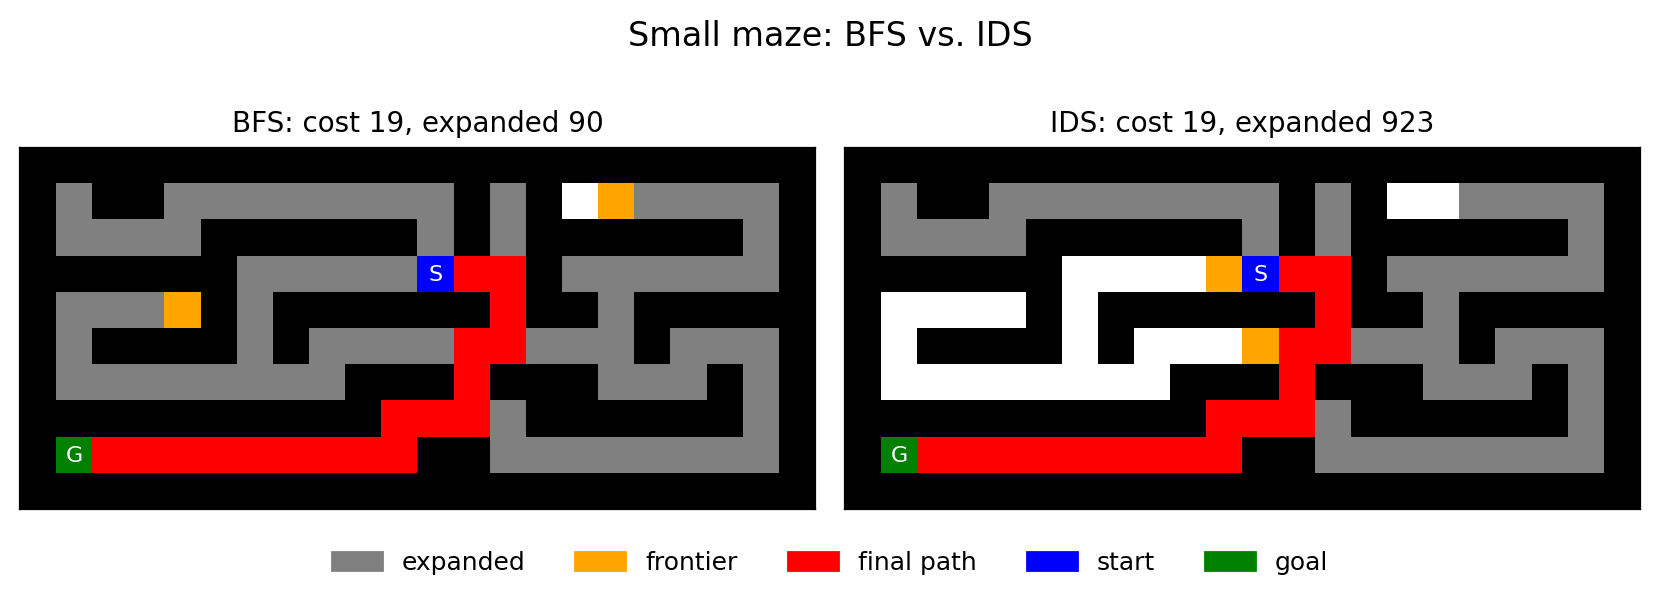

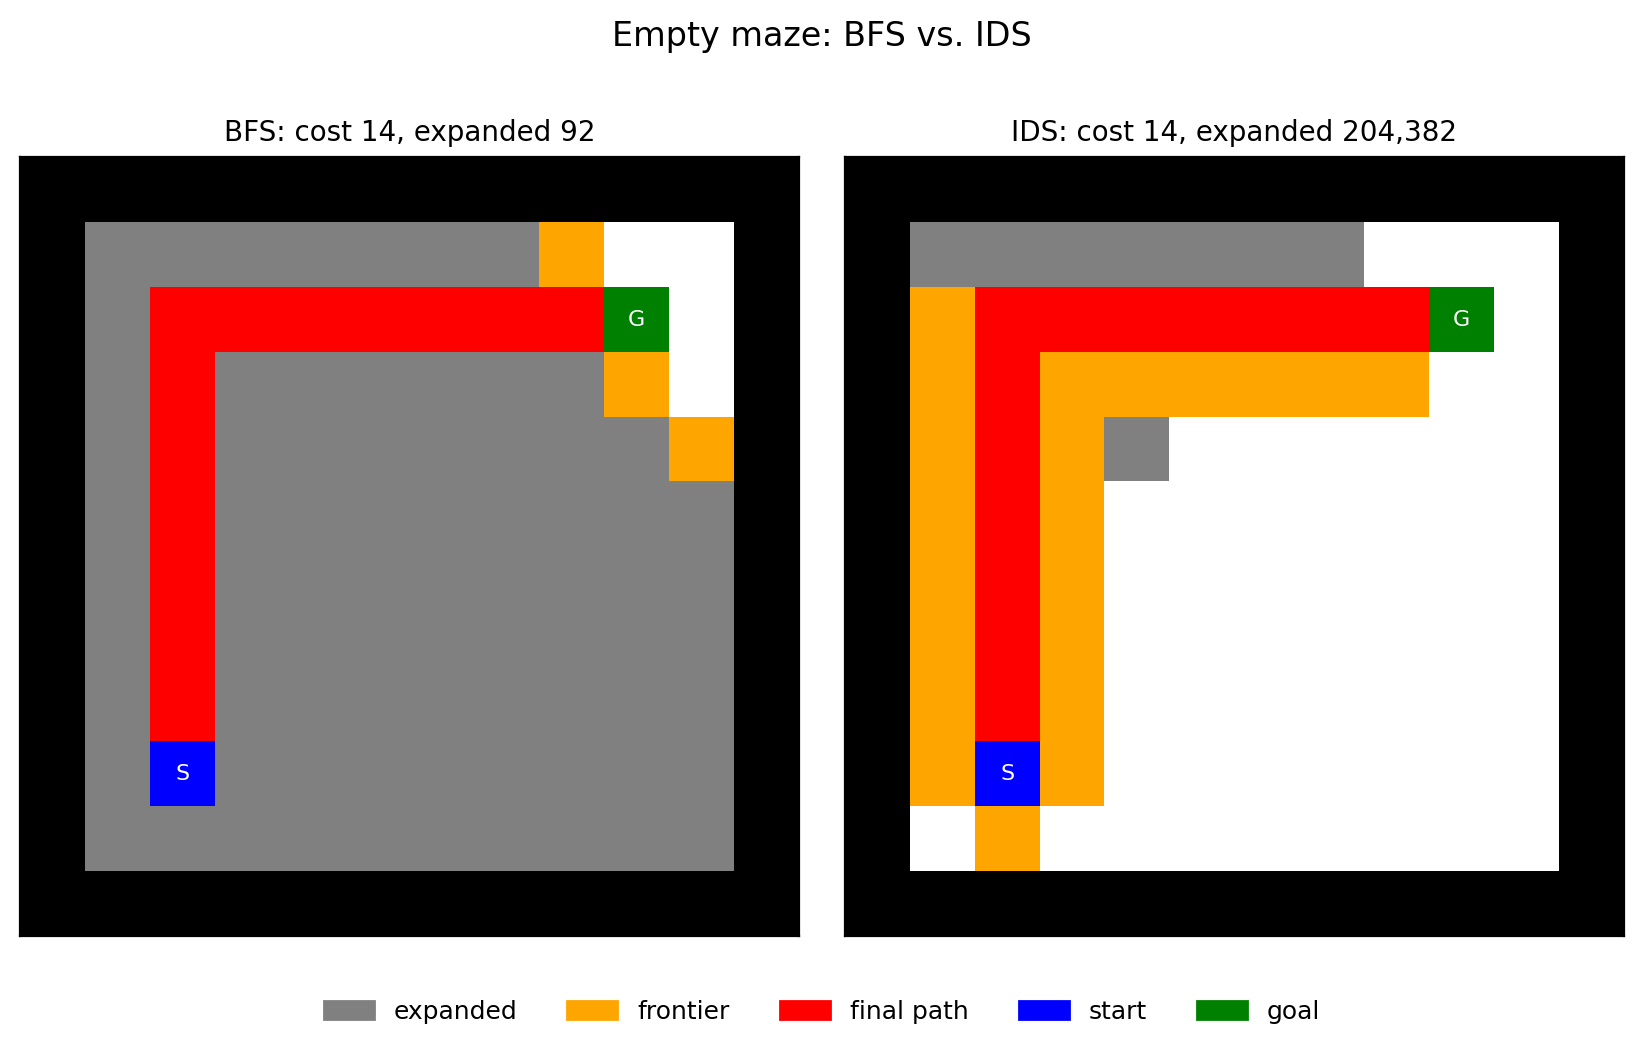

In [ ]:
plot_results(mazes["small"], {"BFS": results["small"]["BFS"], "IDS": ids_results["small"]}, "Small maze: BFS vs. IDS")
plot_results(mazes["empty"], {"BFS": results["empty"]["BFS"], "IDS": ids_results["empty"]}, "Empty maze: BFS vs. IDS")

**Discussion of IDS**

* **Complete and optimal:** yes. IDS looks at all nodes of depth $l$ before depth $l+1$, so the first goal is the shallowest one, which is the cheapest because every step costs 1. All IDS costs equal the BFS costs wherever IDS finished.
* **Memory:** IDS inherits the small memory of DFS: only 77 nodes in memory on the medium maze (BFS: 270) and 242 on the large maze (BFS: 622).
* **Time:** this is the problem. IDS repeats the work of all earlier iterations and, since it has no `reached` table, it also explores every redundant path. On the small maze it expands 923 nodes (BFS: 90), on the **empty maze** 204,382 (BFS: 92) although the goal is only 14 steps away, and on the **loops maze** 78,683 (BFS: 70).
* **Issues with open spaces:** on the **open maze** and the **L maze** IDS did not finish within the limit of 1,000,000 expansions (N/A\*). The cycle check only forbids revisiting a square *on the current path*. In an open area the number of different paths of length $l$ grows exponentially with $l$ (roughly $2.6^l$ self-avoiding walks on a grid), and the optimal depth is 54 (open) and 16 (L) steps. The memory-saving trick of IDS (forgetting everything) therefore turns into an exponential time problem. A fix would need a `reached` table that stores the best depth per state, but then IDS needs $O(n)$ memory and loses its main advantage over BFS.

### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

| maze | optimal cost | algorithm | goal reached | path cost | optimal? | # expanded |
|---|---|---|---|---|---|---|
| medium (1 goal) | 68 | BFS | (16, 1) | 68 | yes | 267 |
| medium (1 goal) | 68 | DFS | (16, 1) | 244 | **no** | 267 |
| medium (1 goal) | 68 | IDS | (16, 1) | 68 | yes | 15,429 |
| medium + goal (1, 10) | 24 | BFS | (1, 10) | 24 | yes | 62 |
| medium + goal (1, 10) | 24 | DFS | (1, 10) | 94 | **no** | 102 |
| medium + goal (1, 10) | 24 | IDS | (1, 10) | 24 | yes | 686 |
| medium + goal (15, 11) | 57 | BFS | (15, 11) | 57 | yes | 221 |
| medium + goal (15, 11) | 57 | DFS | (15, 11) | 233 | **no** | 256 |
| medium + goal (15, 11) | 57 | IDS | (15, 11) | 57 | yes | 8,509 |
| medium + goals (15, 11), (13, 34) | 36 | BFS | (13, 34) | 36 | yes | 122 |
| medium + goals (15, 11), (13, 34) | 36 | DFS | (13, 34) | 36 | yes | 36 |
| medium + goals (15, 11), (13, 34) | 36 | IDS | (13, 34) | 36 | yes | 1,814 |

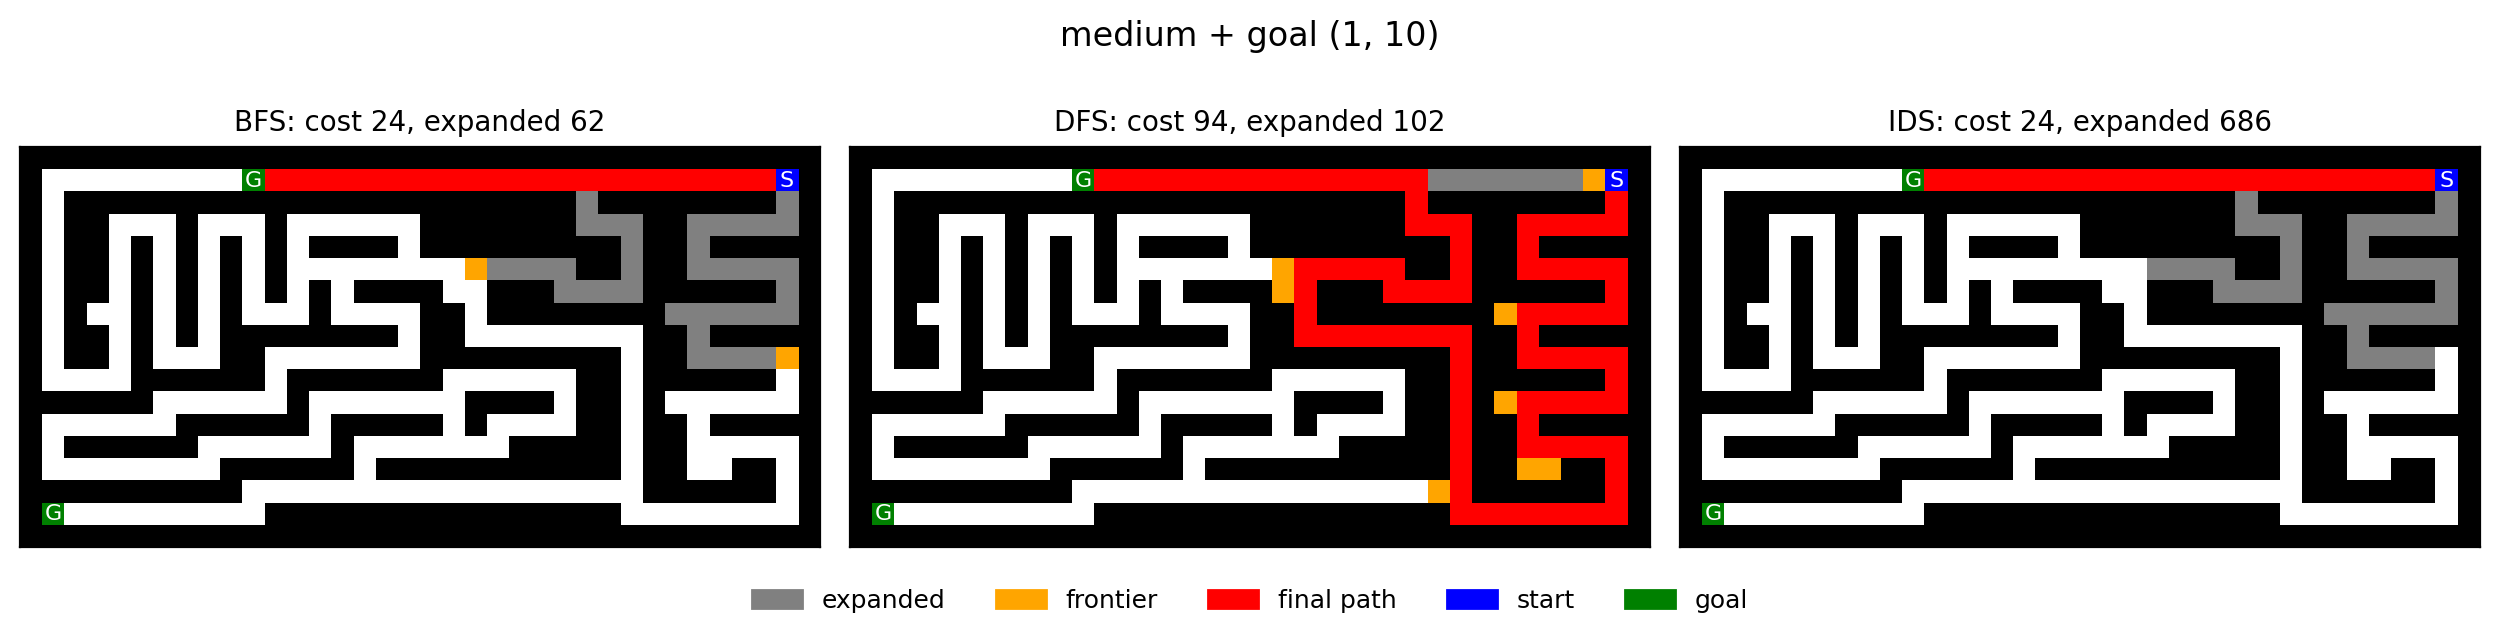

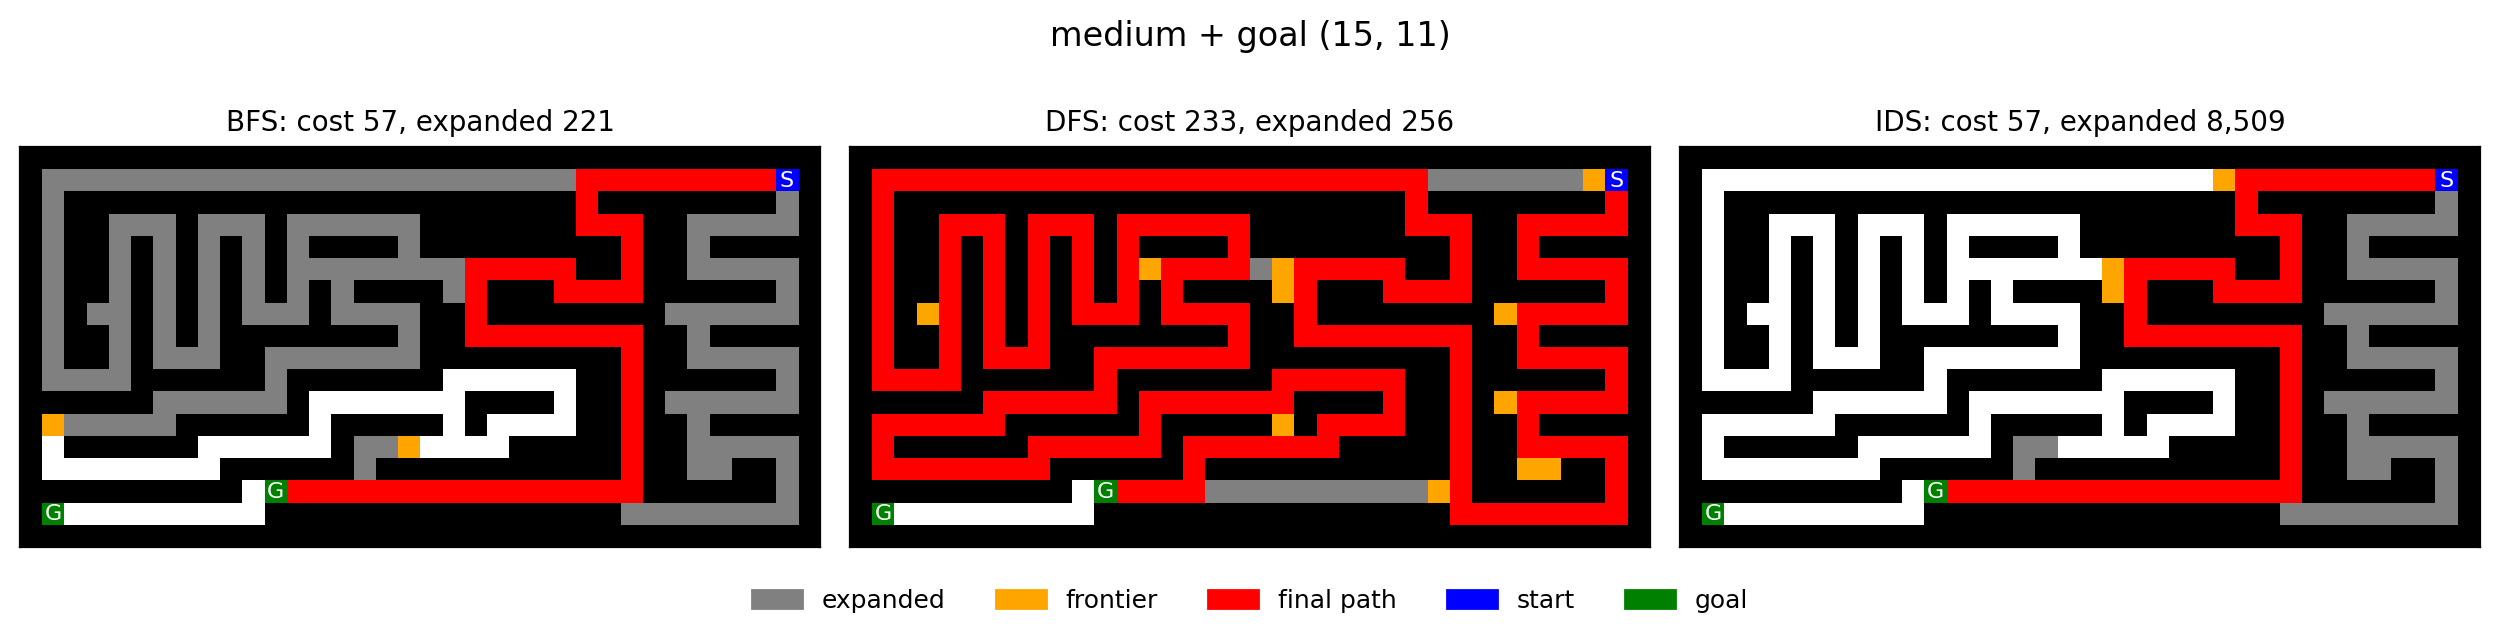

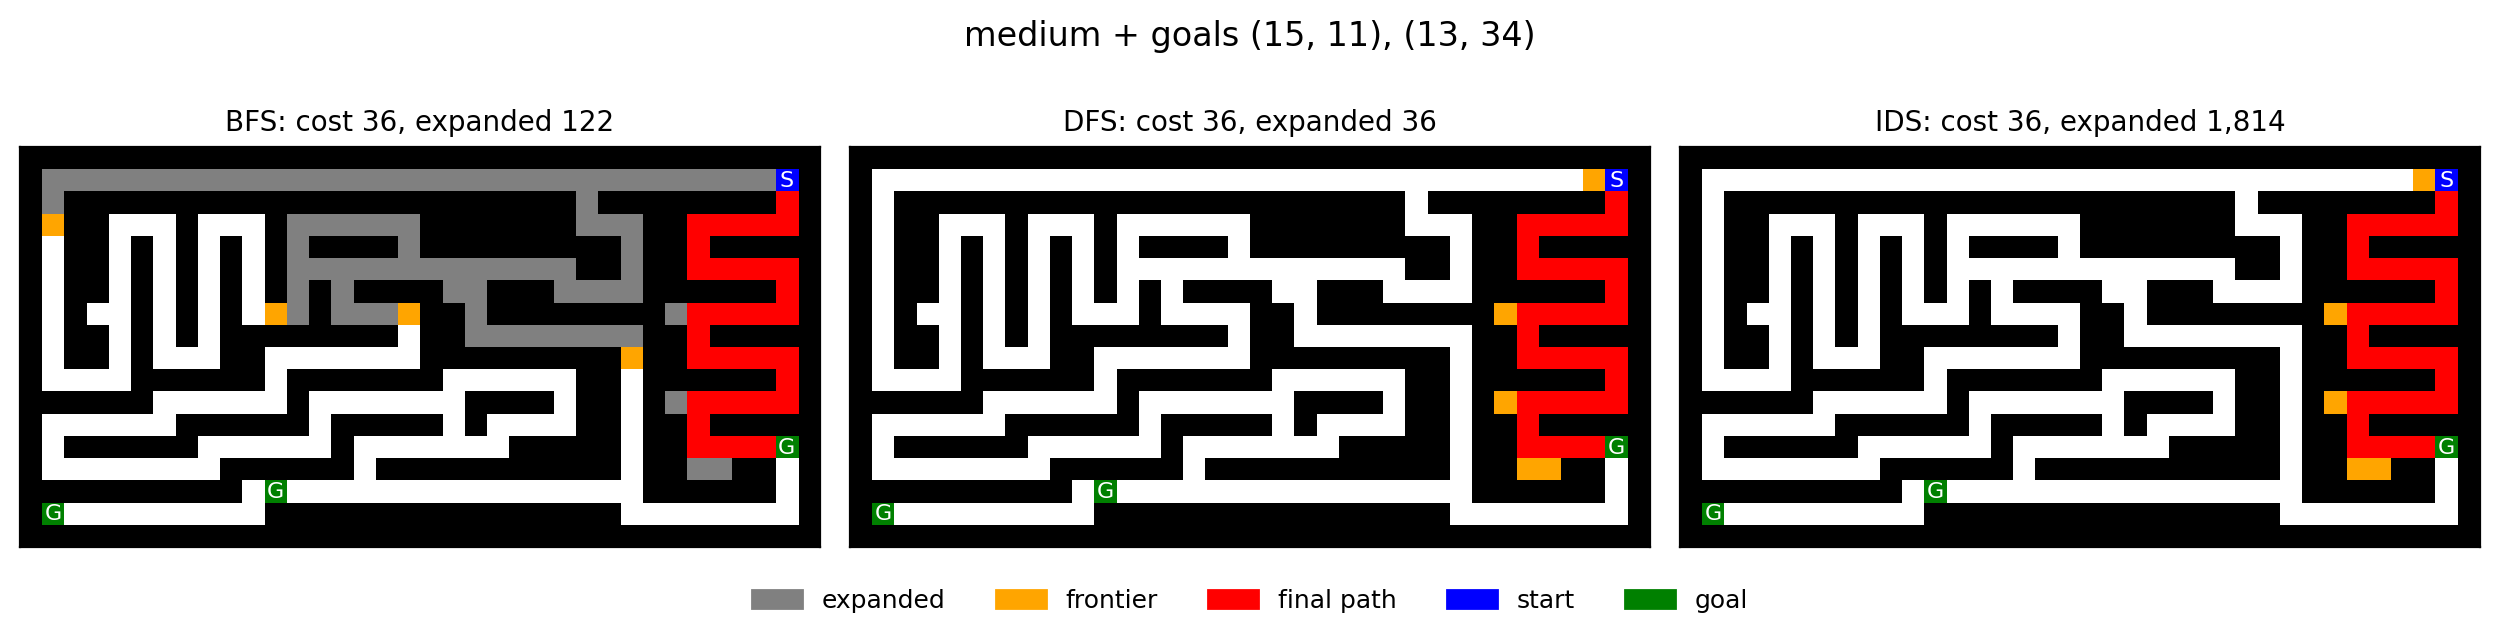

In [28]:
def add_goals(maze, goals):
    """Copy of the maze with additional goal squares."""
    new = np.copy(maze)
    for g in goals:
        assert new[g] == " ", f"{g} is not a free square"
        new[g] = "G"
    return new

# Medium maze: S is at the top right, the original goal G at the bottom left (16, 1).
multi_mazes = {"medium (1 goal)":                    add_goals(mazes["medium"], []),
               "medium + goal (1, 10)":              add_goals(mazes["medium"], [(1, 10)]),
               "medium + goal (15, 11)":             add_goals(mazes["medium"], [(15, 11)]),
               "medium + goals (15, 11), (13, 34)":  add_goals(mazes["medium"], [(15, 11), (13, 34)])}

multi_algs = {"BFS": bfs, "DFS": dfs, "IDS": ids}
multi_results, rows = {}, []
for name, maze in multi_mazes.items():
    start, goals = mh.find_pos(maze, "S"), find_all(maze, "G")
    # true optimum: shortest distance to each single goal (computed separately), then the smallest
    optimum = min(bfs(maze, start, g)["cost"] for g in goals)
    multi_results[name] = {}
    for alg, fn in multi_algs.items():
        r = fn(maze, start, goals)                     # a list of goals: the search is done when ANY goal is reached
        multi_results[name][alg] = r
        rows.append([name, optimum, alg, tuple(r["positions"][-1]), r["cost"],
                     "yes" if r["cost"] == optimum else "**no**", f"{r['expanded']:,}"])

display(Markdown(md_table(["maze", "optimal cost", "algorithm", "goal reached", "path cost", "optimal?", "# expanded"], rows)))
for name in list(multi_mazes)[1:]:
    plot_results(multi_mazes[name], multi_results[name], name)

**Discussion**

* **BFS and IDS always found an optimal solution**, also with several goals. Both look at nodes by increasing depth, so they reach the *closest* goal first, and since every step costs 1 the closest goal is also the cheapest. They do not need to know where the goals are.
* **DFS is not optimal in general.** It returns the first goal it happens to meet. With the extra goal (1, 10) the closest goal is only 24 steps away, but DFS reaches it after 94 steps because its first choices lead it on a long detour. With the goal (15, 11) DFS finds that goal with 233 steps instead of 57. In the last maze DFS is optimal (36 steps), but only because the closest goal, (13, 34), happens to lie on the branch DFS tries first; with another order of actions or other goal positions this would not be the case. More goals make a lucky DFS more likely, but there is no guarantee.
* **A closer goal reduces the work of BFS:** it expands 62 nodes with the goal at (1, 10) instead of 267 with only the original goal. IDS pays for its optimality with repeated work (15,429 expansions for the original goal vs. 267 for BFS).

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [29]:
# Your code/answer goes here

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [30]:
# Your code/answer goes here

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [31]:
# Your code/answer goes here